<a href="https://colab.research.google.com/github/Haidermushtaq/Computer-Vision-/blob/main/CNN_Feature_Visualization_Parameter_Audit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CNN Feature Visualization, Parameter Audit & Critical Analysis
### Deep Learning & Computer Vision Lab Assignment

| | |
|---|---|
| **Student** | Haider Mushtaq |
| **Registration No.** | FA23-BAI-044 |
| **Course** | Deep Learning & Computer Vision (Lab) |


In [1]:
# Section 2: Imports and environment setup
# Everything used here is preinstalled in Google Colab, so no pip install is needed.
import os, sys, time, warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'      # hide TensorFlow info logs (must be set before importing TF)
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from numpy.lib.stride_tricks import sliding_window_view
import cv2
import skimage
from skimage import data as skdata
from skimage.transform import resize
import scipy
from scipy import signal

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Reproducibility: same seed for NumPy, Python and TensorFlow
SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# All figures are saved here so you can put them in your report
FIG_DIR = 'figures'
os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': 200, 'font.size': 10,
                     'axes.titlesize': 10, 'savefig.bbox': 'tight'})
pd.set_option('display.precision', 4)
pd.set_option('display.width', 160)

IN_COLAB = 'google.colab' in sys.modules
print(f"Running in Colab : {IN_COLAB}")
print(f"Python           : {sys.version.split()[0]}")
print(f"NumPy            : {np.__version__}")
print(f"OpenCV           : {cv2.__version__}")
print(f"scikit-image     : {skimage.__version__}")
print(f"TensorFlow/Keras : {tf.__version__} / {keras.__version__}")
print(f"GPU available    : {bool(tf.config.list_physical_devices('GPU'))} (not needed for this lab)")

Running in Colab : True
Python           : 3.13.18
NumPy            : 2.4.6
OpenCV           : 5.0.0
scikit-image     : 0.25.2
TensorFlow/Keras : 2.21.0 / 3.13.2
GPU available    : False (not needed for this lab)


In [2]:
# Section 3a: Build the main test image (a synthetic building facade)
IMG_SIZE = 256

# Known locations of every structure. We use these later to point at exact pixels.
WINDOW_ROWS = [(60, 92), (112, 144)]                       # 2 floors of windows (row start, row end)
WINDOW_COLS = [(32 + i * 52, 64 + i * 52) for i in range(4)]  # 4 windows per floor (col start, col end)
LEDGE_ROWS  = [100, 152]                                   # 3 px dark ledges between floors
BRICK_AREA  = (160, 212)                                   # rows of the brick texture band
SIGN_BOX    = (218, 250, 48, 208)                          # r0, r1, c0, c1 of the "CNN LAB" sign

def make_facade_image(size=IMG_SIZE, noise_std=0.01, seed=SEED):
    """Return a float32 grayscale facade image with values in [0, 1].

    It mimics Figure 2 of the assignment: strong horizontal and vertical edges
    (windows, ledges), diagonal edges (roof), a smooth gradient (sky),
    a repeating texture (bricks), thin 1 px lines (window mullions)
    and dark text on a white board (useful for Question 2).
    """
    if size != 256:
        raise ValueError("The facade layout is designed for a 256 x 256 canvas.")
    rng = np.random.default_rng(seed)
    img = np.zeros((size, size), dtype=np.float64)

    img[:48, :] = np.linspace(0.95, 0.70, 48)[:, None]    # 1) sky: smooth vertical gradient
    img[48:, :] = 0.55                                     # ground on both sides of the building
    img[48:, 16:240] = 0.78                                # 2) light building wall

    for r in range(20, 48):                                # 3) dark triangular roof (diagonal edges)
        half = int((r - 20) / 28 * 112)
        img[r, 128 - half:128 + half] = 0.30

    for r0 in LEDGE_ROWS:                                  # 4) dark floor ledges
        img[r0:r0 + 3, 16:240] = 0.30

    for (r0, r1) in WINDOW_ROWS:                           # 5) dark windows with bright 1 px mullions
        for (c0, c1) in WINDOW_COLS:
            img[r0:r1, c0:c1] = 0.12
            img[r0:r1, c0 + 16] = 0.95                     # vertical mullion
            img[r0 + 16, c0:c1] = 0.95                     # horizontal mullion

    b0, b1 = BRICK_AREA                                    # 6) brick texture (repeating pattern)
    img[b0:b1, 16:240] = 0.85                              # mortar colour
    for k, r in enumerate(range(b0, b1, 8)):
        offset = 0 if k % 2 == 0 else 12
        for c in range(16 - offset, 240, 24):
            cs, ce = max(c, 16), min(c + 22, 240)
            if ce > cs:
                img[r:min(r + 7, b1), cs:ce] = 0.50

    r0, r1, c0, c1 = SIGN_BOX                              # 7) white sign with dark 1-2 px text
    board = np.full((r1 - r0, c1 - c0), 255, np.uint8)
    cv2.putText(board, 'CNN LAB', (14, 24), cv2.FONT_HERSHEY_SIMPLEX, 0.85, 15, 1, cv2.LINE_8)
    img[r0:r1, c0:c1] = board / 255.0

    img += rng.normal(0.0, noise_std, img.shape)            # 8) a little sensor noise
    return np.clip(img, 0.0, 1.0).astype(np.float32)

facade = make_facade_image()
print("facade:", facade.shape, facade.dtype, f"min={facade.min():.3f} max={facade.max():.3f}")

facade: (256, 256) float32 min=0.035 max=1.000


In [3]:
# Section 3b: Choose the image for Part I (with error handling)
USE_OWN_IMAGE = False   # set to True to upload your own photo (any size, colour or grayscale)

def preprocess_to_gray(img_array, size=IMG_SIZE):
    """Any image -> square, grayscale, float32 in [0, 1], size x size."""
    if img_array is None or img_array.size == 0:
        raise ValueError("Empty image.")
    img = img_array.astype(np.float32)
    if img.ndim == 3:                                    # colour -> grayscale (ITU-R 601 luma weights)
        if img.shape[2] == 4:
            img = img[..., :3]
        img = img[..., 0] * 0.299 + img[..., 1] * 0.587 + img[..., 2] * 0.114
    if img.max() > 1.0:                                  # uint8 style range -> [0, 1]
        img = img / 255.0
    h, w = img.shape                                     # centre crop to a square
    s = min(h, w)
    img = img[(h - s) // 2:(h - s) // 2 + s, (w - s) // 2:(w - s) // 2 + s]
    img = resize(img, (size, size), anti_aliasing=True, preserve_range=True)
    return np.clip(img, 0, 1).astype(np.float32)

def load_uploaded_image():
    """Upload an image in Colab and preprocess it. Returns None if anything fails."""
    try:
        from google.colab import files
        uploaded = files.upload()
        if not uploaded:
            print("No file uploaded.")
            return None
        name, raw = next(iter(uploaded.items()))
        arr = cv2.imdecode(np.frombuffer(raw, np.uint8), cv2.IMREAD_COLOR)
        if arr is None:
            print(f"Could not decode '{name}'. Is it a valid image file?")
            return None
        arr = cv2.cvtColor(arr, cv2.COLOR_BGR2RGB)
        print(f"Loaded '{name}' with shape {arr.shape}")
        return preprocess_to_gray(arr)
    except Exception as e:
        print(f"Upload failed ({type(e).__name__}: {e}).")
        return None

image = None
if USE_OWN_IMAGE:
    image = load_uploaded_image()
if image is None:
    image = facade
    print("Using the synthetic facade image (default).")

# A real photograph for a sanity check. It ships inside scikit-image, so no internet is needed.
try:
    real_photo = preprocess_to_gray(skdata.camera())
except Exception as e:
    print(f"Could not load the sample photo ({e}); falling back to the facade.")
    real_photo = facade.copy()

# Dimension and range checks: the rest of the notebook depends on these
for nm, im in [('image', image), ('real_photo', real_photo)]:
    assert im.shape == (IMG_SIZE, IMG_SIZE), f"{nm} has wrong shape {im.shape}"
    assert im.dtype == np.float32 and 0.0 <= im.min() and im.max() <= 1.0
    print(f"{nm:10s} shape={im.shape} dtype={im.dtype} range=[{im.min():.3f}, {im.max():.3f}]")

Using the synthetic facade image (default).
image      shape=(256, 256) dtype=float32 range=[0.035, 1.000]
real_photo shape=(256, 256) dtype=float32 range=[0.008, 0.999]


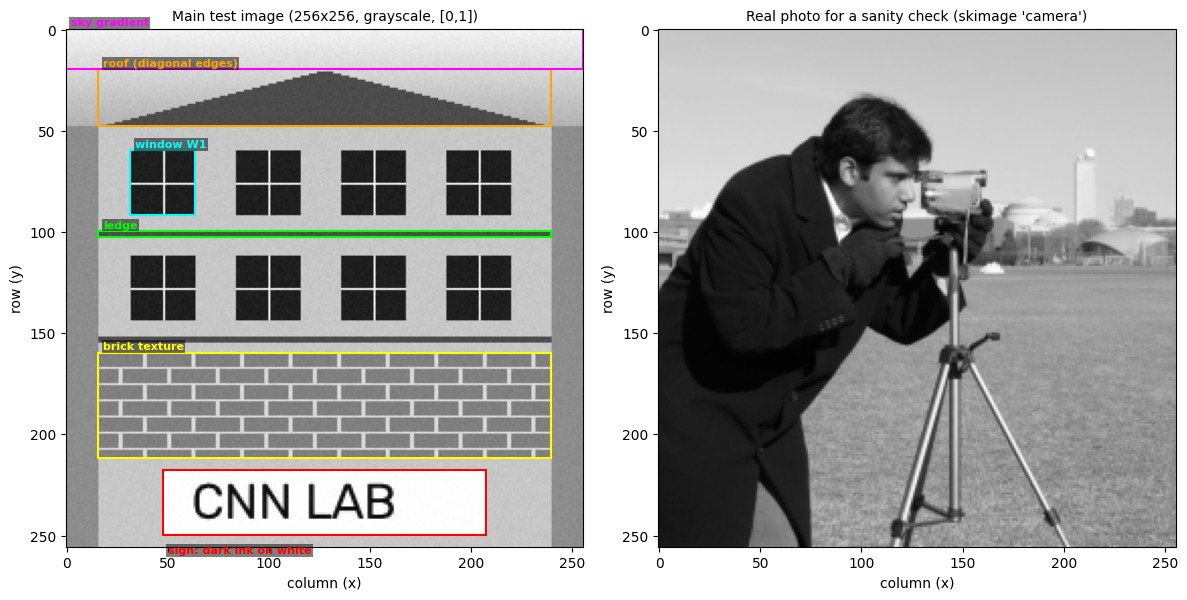

Row 70, columns 26..37 (wall -> left edge of window W1):
[0.78 0.77 0.76 0.77 0.8  0.78 0.14 0.14 0.15 0.14 0.14 0.12]


In [4]:
# Section 3c: Look at the inputs
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
ax = axes[0]
ax.imshow(image, cmap='gray', vmin=0, vmax=1)
ax.set_title(f"Main test image ({image.shape[0]}x{image.shape[1]}, grayscale, [0,1])")
if image is facade:   # label the known structures so later answers can refer to them
    (wr0, wr1), (wc0, wc1) = WINDOW_ROWS[0], WINDOW_COLS[0]
    labels = [((20, 16, 28, 224), 'roof (diagonal edges)', 'orange'),
              ((wr0, wc0, wr1 - wr0, wc1 - wc0), 'window W1', 'cyan'),
              ((LEDGE_ROWS[0], 16, 3, 224), 'ledge', 'lime'),
              ((BRICK_AREA[0], 16, BRICK_AREA[1] - BRICK_AREA[0], 224), 'brick texture', 'yellow'),
              ((SIGN_BOX[0], SIGN_BOX[2], SIGN_BOX[1] - SIGN_BOX[0], SIGN_BOX[3] - SIGN_BOX[2]), 'sign: dark ink on white', 'red'),
              ((0, 0, 20, 256), 'sky gradient', 'magenta')]
    for (r, c, h, w), txt, col in labels:
        ax.add_patch(Rectangle((c - 0.5, r - 0.5), w, h, fill=False, ec=col, lw=1.5))
        ax.text(c + 2, r + h + 9 if r > 200 else r - 2, txt, color=col, fontsize=8, weight='bold',
                bbox=dict(fc='black', alpha=0.5, pad=1, lw=0))
axes[1].imshow(real_photo, cmap='gray', vmin=0, vmax=1)
axes[1].set_title("Real photo for a sanity check (skimage 'camera')")
for a in axes:
    a.set_xlabel('column (x)'); a.set_ylabel('row (y)')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/fig0_input_images.png')
plt.show()

# Print a few real pixel values so you know what "bright" and "dark" mean numerically
r = 70
print(f"Row {r}, columns 26..37 (wall -> left edge of window W1):")
print(np.round(image[r, 26:38], 2))

1. Horizontal-gradient edge (Sobel-X)    sum=+0.00  min=-2.000  max=+2.000  has negative weights: True
2. Vertical-gradient edge (Sobel-Y)      sum=+0.00  min=-2.000  max=+2.000  has negative weights: True
3. Sharpen                               sum=+1.00  min=-1.000  max=+5.000  has negative weights: True
4. Gaussian blur                         sum=+1.00  min=+0.062  max=+0.250  has negative weights: False
5. Emboss                                sum=+1.00  min=-2.000  max=+2.000  has negative weights: True


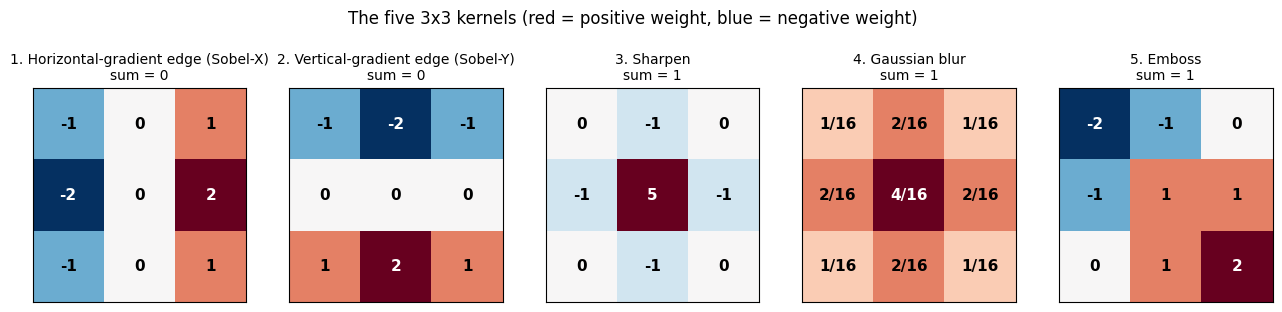

In [5]:
# Section 4: The five custom 3x3 kernels
FILTERS = {
    'sobel_x': dict(name='1. Horizontal-gradient edge (Sobel-X)',
                    kernel=np.array([[-1, 0, 1],
                                     [-2, 0, 2],
                                     [-1, 0, 1]], dtype=np.float32)),
    'sobel_y': dict(name='2. Vertical-gradient edge (Sobel-Y)',
                    kernel=np.array([[-1, -2, -1],
                                     [ 0,  0,  0],
                                     [ 1,  2,  1]], dtype=np.float32)),
    'sharpen': dict(name='3. Sharpen',
                    kernel=np.array([[ 0, -1,  0],
                                     [-1,  5, -1],
                                     [ 0, -1,  0]], dtype=np.float32)),
    'blur':    dict(name='4. Gaussian blur',
                    kernel=np.array([[1, 2, 1],
                                     [2, 4, 2],
                                     [1, 2, 1]], dtype=np.float32) / 16.0),
    'emboss':  dict(name='5. Emboss',
                    kernel=np.array([[-2, -1, 0],
                                     [-1,  1, 1],
                                     [ 0,  1, 2]], dtype=np.float32)),
}

for key, f in FILTERS.items():
    k = f['kernel']
    assert k.shape == (3, 3)
    print(f"{f['name']:40s} sum={k.sum():+.2f}  min={k.min():+.3f}  max={k.max():+.3f}  "
          f"has negative weights: {bool((k < 0).any())}")

fig, axes = plt.subplots(1, 5, figsize=(16, 3.4))
for ax, (key, f) in zip(axes, FILTERS.items()):
    k = f['kernel']; lim = np.abs(k).max()
    ax.imshow(k, cmap='RdBu_r', vmin=-lim, vmax=lim)
    for (i, j), v in np.ndenumerate(k):
        ax.text(j, i, f"{v:g}" if key != 'blur' else f"{int(v * 16)}/16", ha='center', va='center',
                fontsize=11, weight='bold', color='white' if abs(v) > 0.6 * lim else 'black')
    ax.set_title(f"{f['name']}\nsum = {k.sum():g}")
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle('The five 3x3 kernels (red = positive weight, blue = negative weight)', y=1.04)
plt.savefig(f'{FIG_DIR}/fig1_kernels.png')
plt.show()

In [6]:
# Section 5: Convolution implementation (from scratch) + verification

def conv2d_loop(img, kernel):
    """Teaching version: two plain for-loops, 'valid' output (no padding).
    out[i, j] = sum over (u, v) of img[i+u, j+v] * kernel[u, v]
    This is cross-correlation, which is exactly what CNN layers compute."""
    kh, kw = kernel.shape
    H, W = img.shape
    out = np.zeros((H - kh + 1, W - kw + 1), dtype=np.float32)
    for i in range(out.shape[0]):
        for j in range(out.shape[1]):
            patch = img[i:i + kh, j:j + kw]          # the 3x3 window under the kernel
            out[i, j] = np.sum(patch * kernel)      # multiply element-wise, then add up
    return out

def conv2d(img, kernel, padding='reflect'):
    """Fast version used in the pipeline.
    padding='reflect' keeps the output the same size as the input (like 'same')
    without inventing fake edges at the border. padding=None gives 'valid' output."""
    kh, kw = kernel.shape
    if padding is not None:
        img = np.pad(img, ((kh // 2, kh // 2), (kw // 2, kw // 2)), mode=padding)
    windows = sliding_window_view(img, (kh, kw))            # shape (H, W, 3, 3): every 3x3 patch
    return np.einsum('ijuv,uv->ij', windows, kernel).astype(np.float32)

# --- Check 1: a tiny example you can verify by hand -----------------------
toy = np.array([[10, 10, 10, 80, 80],
                [10, 10, 10, 80, 80],
                [10, 10, 10, 80, 80],
                [10, 10, 10, 80, 80]], dtype=np.float32)    # dark | bright vertical boundary
kx = FILTERS['sobel_x']['kernel']
print("Toy image (dark on the left, bright on the right):\n", toy)
print("\nSobel-X, loop version (valid):\n", conv2d_loop(toy, kx))
print("Vectorised version (valid):\n", conv2d(toy, kx, padding=None))
# By hand for out[0,0]: (-1*10 + 0*10 + 1*10) + (-2*10 + 0 + 2*10) + (-1*10 + 0 + 1*10) = 0
# For out[0,1]:        (-1*10 + 1*80) + (-2*10 + 2*80) + (-1*10 + 1*80) = 70 + 140 + 70 = 280

# --- Check 2: matches TensorFlow's Conv2D maths on the real image ----------
for key, f in FILTERS.items():
    ours = conv2d(image, f['kernel'], padding=None)
    tf_out = tf.nn.conv2d(image[None, :, :, None], f['kernel'][:, :, None, None],
                          strides=1, padding='VALID').numpy()[0, :, :, 0]
    assert ours.shape == tf_out.shape == (IMG_SIZE - 2, IMG_SIZE - 2)
    assert np.allclose(ours, tf_out, atol=1e-4), key
print("\nOur conv2d matches tf.nn.conv2d for all 5 kernels (max error < 1e-4).")

# --- Check 3: 'true' convolution flips the kernel, which flips Sobel's sign --
true_conv = signal.convolve2d(toy, kx, mode='valid')
print("\nscipy.signal.convolve2d (kernel flipped) on the toy image:\n", true_conv)
print("Same magnitude, opposite sign. CNN frameworks do NOT flip, so we follow them.")

Toy image (dark on the left, bright on the right):
 [[10. 10. 10. 80. 80.]
 [10. 10. 10. 80. 80.]
 [10. 10. 10. 80. 80.]
 [10. 10. 10. 80. 80.]]

Sobel-X, loop version (valid):
 [[  0. 280. 280.]
 [  0. 280. 280.]]
Vectorised version (valid):
 [[  0. 280. 280.]
 [  0. 280. 280.]]

Our conv2d matches tf.nn.conv2d for all 5 kernels (max error < 1e-4).

scipy.signal.convolve2d (kernel flipped) on the toy image:
 [[   0. -280. -280.]
 [   0. -280. -280.]]
Same magnitude, opposite sign. CNN frameworks do NOT flip, so we follow them.


In [7]:
# Section 6: ReLU activation
def relu(x):
    """ReLU(x) = max(0, x), applied to every pixel independently."""
    return np.maximum(0.0, x)

demo = np.array([-2.6, -0.4, 0.0, 0.3, 2.6], dtype=np.float32)
print("x       :", demo)
print("ReLU(x) :", relu(demo))
assert np.allclose(relu(image[:8, :8] - 0.5), tf.nn.relu(image[:8, :8] - 0.5).numpy())

x       : [-2.6 -0.4  0.   0.3  2.6]
ReLU(x) : [0.  0.  0.  0.3 2.6]


In [8]:
# Section 7: Max pooling and average pooling (2x2, stride 2)
def pool2d(x, size=2, stride=2, mode='max'):
    """Slide a size x size window with the given stride and keep the max or the mean.
    Output size = floor((H - size) / stride) + 1, so an odd last row/column is dropped
    (the same rule as Keras 'valid' pooling)."""
    windows = sliding_window_view(x, (size, size))[::stride, ::stride]   # (H/2, W/2, 2, 2)
    if mode == 'max':
        return windows.max(axis=(-2, -1)).astype(np.float32)
    if mode == 'avg':
        return windows.mean(axis=(-2, -1)).astype(np.float32)
    if mode == 'min':
        return windows.min(axis=(-2, -1)).astype(np.float32)
    raise ValueError(mode)

patch = np.array([[1, 3, 0, 0],
                  [2, 8, 0, 4],
                  [5, 0, 6, 6],
                  [1, 2, 6, 6]], dtype=np.float32)
print("4x4 input:\n", patch)
print("Max pool  :\n", pool2d(patch, mode='max'))
print("Avg pool  :\n", pool2d(patch, mode='avg'))

# Verify against TensorFlow on a real feature map
test_map = relu(conv2d(image, FILTERS['sharpen']['kernel']))
tf_max = tf.nn.max_pool2d(test_map[None, :, :, None], 2, 2, 'VALID').numpy()[0, :, :, 0]
tf_avg = tf.nn.avg_pool2d(test_map[None, :, :, None], 2, 2, 'VALID').numpy()[0, :, :, 0]
assert np.allclose(pool2d(test_map, mode='max'), tf_max) and np.allclose(pool2d(test_map, mode='avg'), tf_avg, atol=1e-6)
print(f"\nMatches tf.nn.max_pool2d / avg_pool2d. Shape {test_map.shape} -> {tf_max.shape}")

4x4 input:
 [[1. 3. 0. 0.]
 [2. 8. 0. 4.]
 [5. 0. 6. 6.]
 [1. 2. 6. 6.]]
Max pool  :
 [[8. 4.]
 [5. 6.]]
Avg pool  :
 [[3.5 1. ]
 [2.  6. ]]

Matches tf.nn.max_pool2d / avg_pool2d. Shape (256, 256) -> (128, 128)


In [9]:
# Section 8a: Run the 4-stage pipeline for every filter
def run_pipeline(img, kernel):
    A = conv2d(img, kernel)          # Stage A: raw convolution (linear, can be negative)
    B = relu(A)                      # Stage B: ReLU
    C = pool2d(B, mode='max')        # Stage C: max pooling of the post-ReLU map
    D = pool2d(B, mode='avg')        # Stage D: average pooling of the post-ReLU map
    return {'A': A, 'B': B, 'C': C, 'D': D}

results = {key: run_pipeline(image, f['kernel']) for key, f in FILTERS.items()}
results_photo = {key: run_pipeline(real_photo, f['kernel']) for key, f in FILTERS.items()}

# Dimension check at every stage
for key, st in results.items():
    assert st['A'].shape == st['B'].shape == (IMG_SIZE, IMG_SIZE)
    assert st['C'].shape == st['D'].shape == (IMG_SIZE // 2, IMG_SIZE // 2)
    assert (st['B'] >= 0).all() and (st['C'] >= st['D'] - 1e-6).all()   # ReLU >= 0, max >= mean
print("Stage shapes:", {s: results['sobel_x'][s].shape for s in 'ABCD'})

Stage shapes: {'A': (256, 256), 'B': (256, 256), 'C': (128, 128), 'D': (128, 128)}


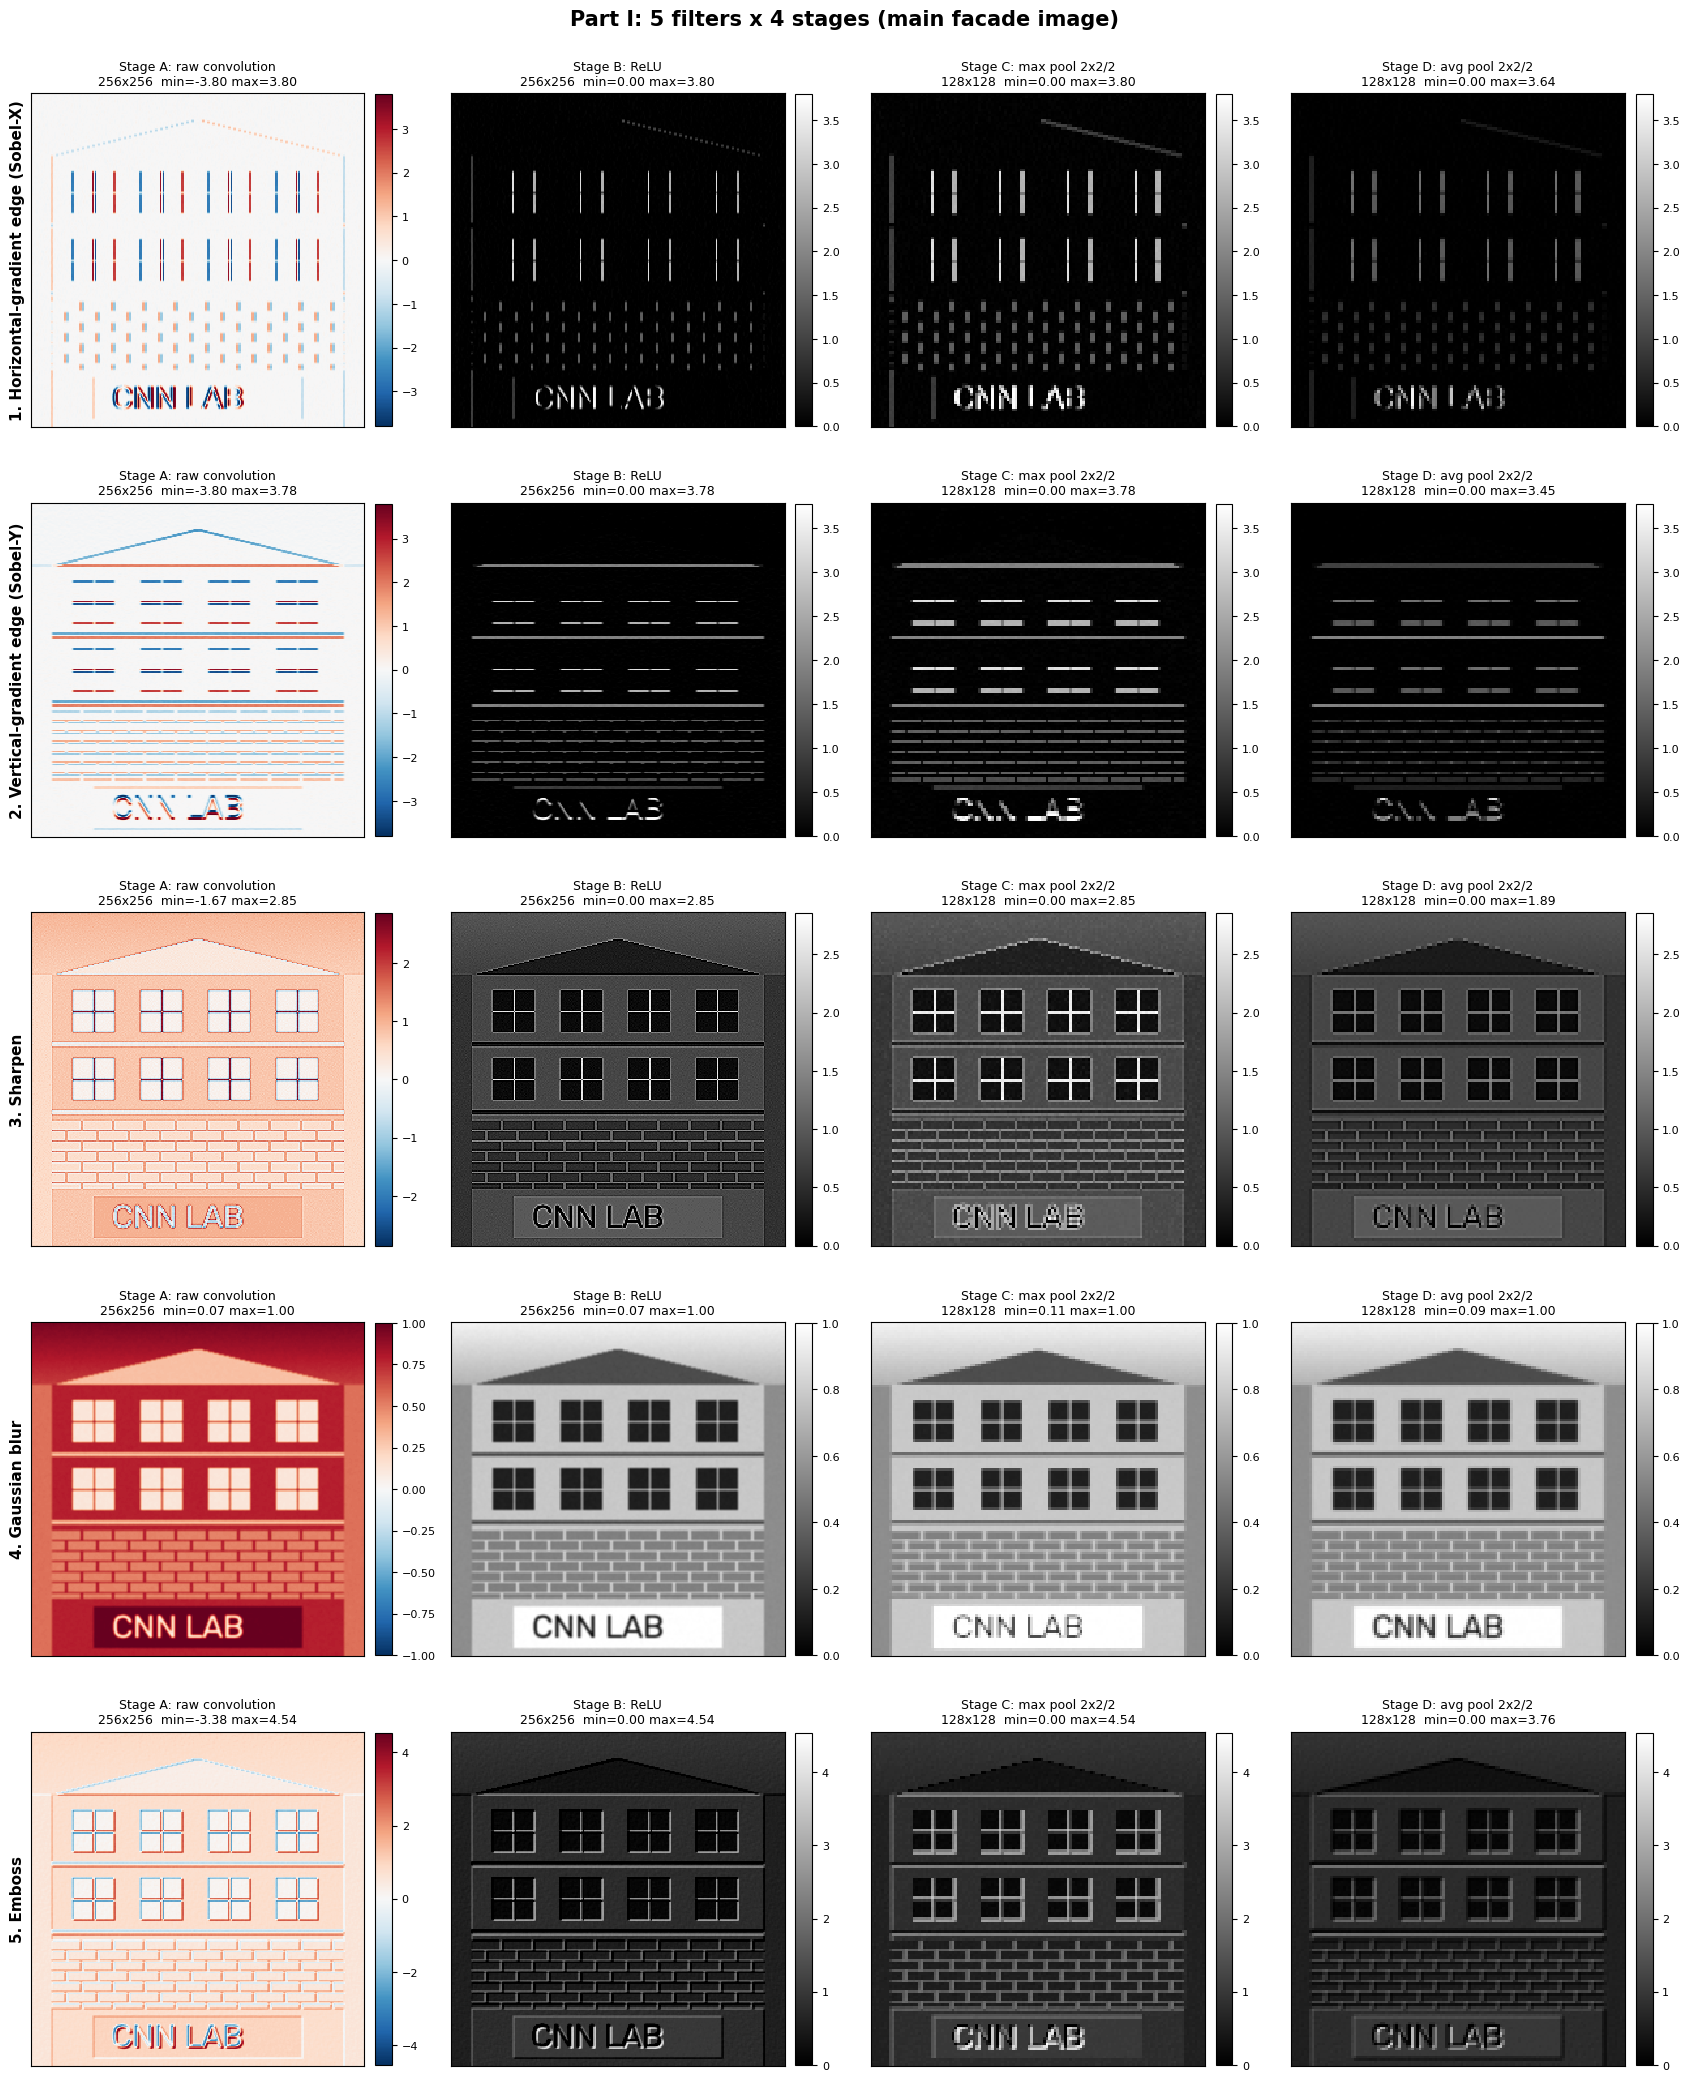

In [10]:
# Section 8b: The unified 5 x 4 visualisation grid
STAGE_TITLES = {'A': 'Stage A: raw convolution',
                'B': 'Stage B: ReLU',
                'C': 'Stage C: max pool 2x2/2',
                'D': 'Stage D: avg pool 2x2/2'}

def plot_grid(res, title, filename):
    """5 rows (filters) x 4 columns (stages).
    Scaling rules, chosen so that comparisons are fair:
      * Stage A uses a diverging map (blue < 0 < red) with symmetric limits +-max|A|,
        so you can SEE which pixels are negative.
      * Stages B, C and D share ONE grayscale range [0, max(B)] per row,
        so a pixel that looks dimmer in D than in C really is dimmer."""
    fig, axes = plt.subplots(5, 4, figsize=(17, 21))
    for r, (key, st) in enumerate(res.items()):
        a_lim = max(np.abs(st['A']).max(), 1e-6)
        b_max = max(st['B'].max(), 1e-6)
        for c, s in enumerate('ABCD'):
            ax = axes[r, c]
            if s == 'A':
                im = ax.imshow(st[s], cmap='RdBu_r', vmin=-a_lim, vmax=a_lim, interpolation='nearest')
            else:
                im = ax.imshow(st[s], cmap='gray', vmin=0, vmax=b_max, interpolation='nearest')
            cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
            cb.ax.tick_params(labelsize=8)
            ax.set_title(f"{STAGE_TITLES[s]}\n{st[s].shape[0]}x{st[s].shape[1]}  "
                         f"min={st[s].min():.2f} max={st[s].max():.2f}", fontsize=9)
            ax.set_xticks([]); ax.set_yticks([])
            if c == 0:
                ax.set_ylabel(FILTERS[key]['name'], fontsize=11, weight='bold')
    fig.suptitle(title, fontsize=15, weight='bold', y=0.995)
    plt.tight_layout()
    plt.savefig(f'{FIG_DIR}/{filename}')
    plt.show()

plot_grid(results, 'Part I: 5 filters x 4 stages (main facade image)', 'fig2_grid_5x4_facade.png')

In [11]:
# Section 9a: Numbers behind the grid
rows = []
for key, st in results.items():
    A = st['A']
    neg_energy = np.abs(A[A < 0]).sum() / max(np.abs(A).sum(), 1e-12)
    rows.append({
        'filter': FILTERS[key]['name'],
        'kernel sum': FILTERS[key]['kernel'].sum(),
        'A min': A.min(), 'A max': A.max(),
        '% pixels < 0 in A': 100 * (A < 0).mean(),
        '% of strong responses (|A|>0.5) < 0': 100 * (A[np.abs(A) > 0.5] < 0).mean() if (np.abs(A) > 0.5).any() else 0.0,
        '% of |A| removed by ReLU': 100 * neg_energy,
        'mean B': st['B'].mean(),
        'mean C (max)': st['C'].mean(),
        'mean D (avg)': st['D'].mean(),
        'max C': st['C'].max(),
        'max D': st['D'].max(),
    })
stats = pd.DataFrame(rows).set_index('filter')
stats.to_csv(f'{FIG_DIR}/table_stage_statistics.csv')
stats

,kernel sum,A min,A max,% pixels < 0 in A,% of strong responses (|A|>0.5) < 0,% of |A| removed by ReLU,mean B,mean C (max),mean D (avg),max C,max D
filter,,,,,,,,,,,
1. Horizontal-gradient edge (Sobel-X),0.0,-3.7991,3.8021,49.5331,49.8275,50.0026,0.0879,0.1847,0.0879,3.8021,3.6449
2. Vertical-gradient edge (Sobel-Y),0.0,-3.8014,3.7807,54.7195,50.7639,51.1311,0.1326,0.2428,0.1326,3.7807,3.4520
3. Sharpen,1.0,-1.6731,2.8537,6.1401,4.4471,4.2303,0.6578,0.8177,0.6578,2.8537,1.8944
4. Gaussian blur,1.0,0.0715,1.0000,0.0000,0.0000,0.0000,0.6287,0.6535,0.6287,1.0000,0.9998
5. Emboss,1.0,-3.3835,4.5414,8.6975,8.7279,10.6004,0.7081,0.9095,0.7081,4.5414,3.7574


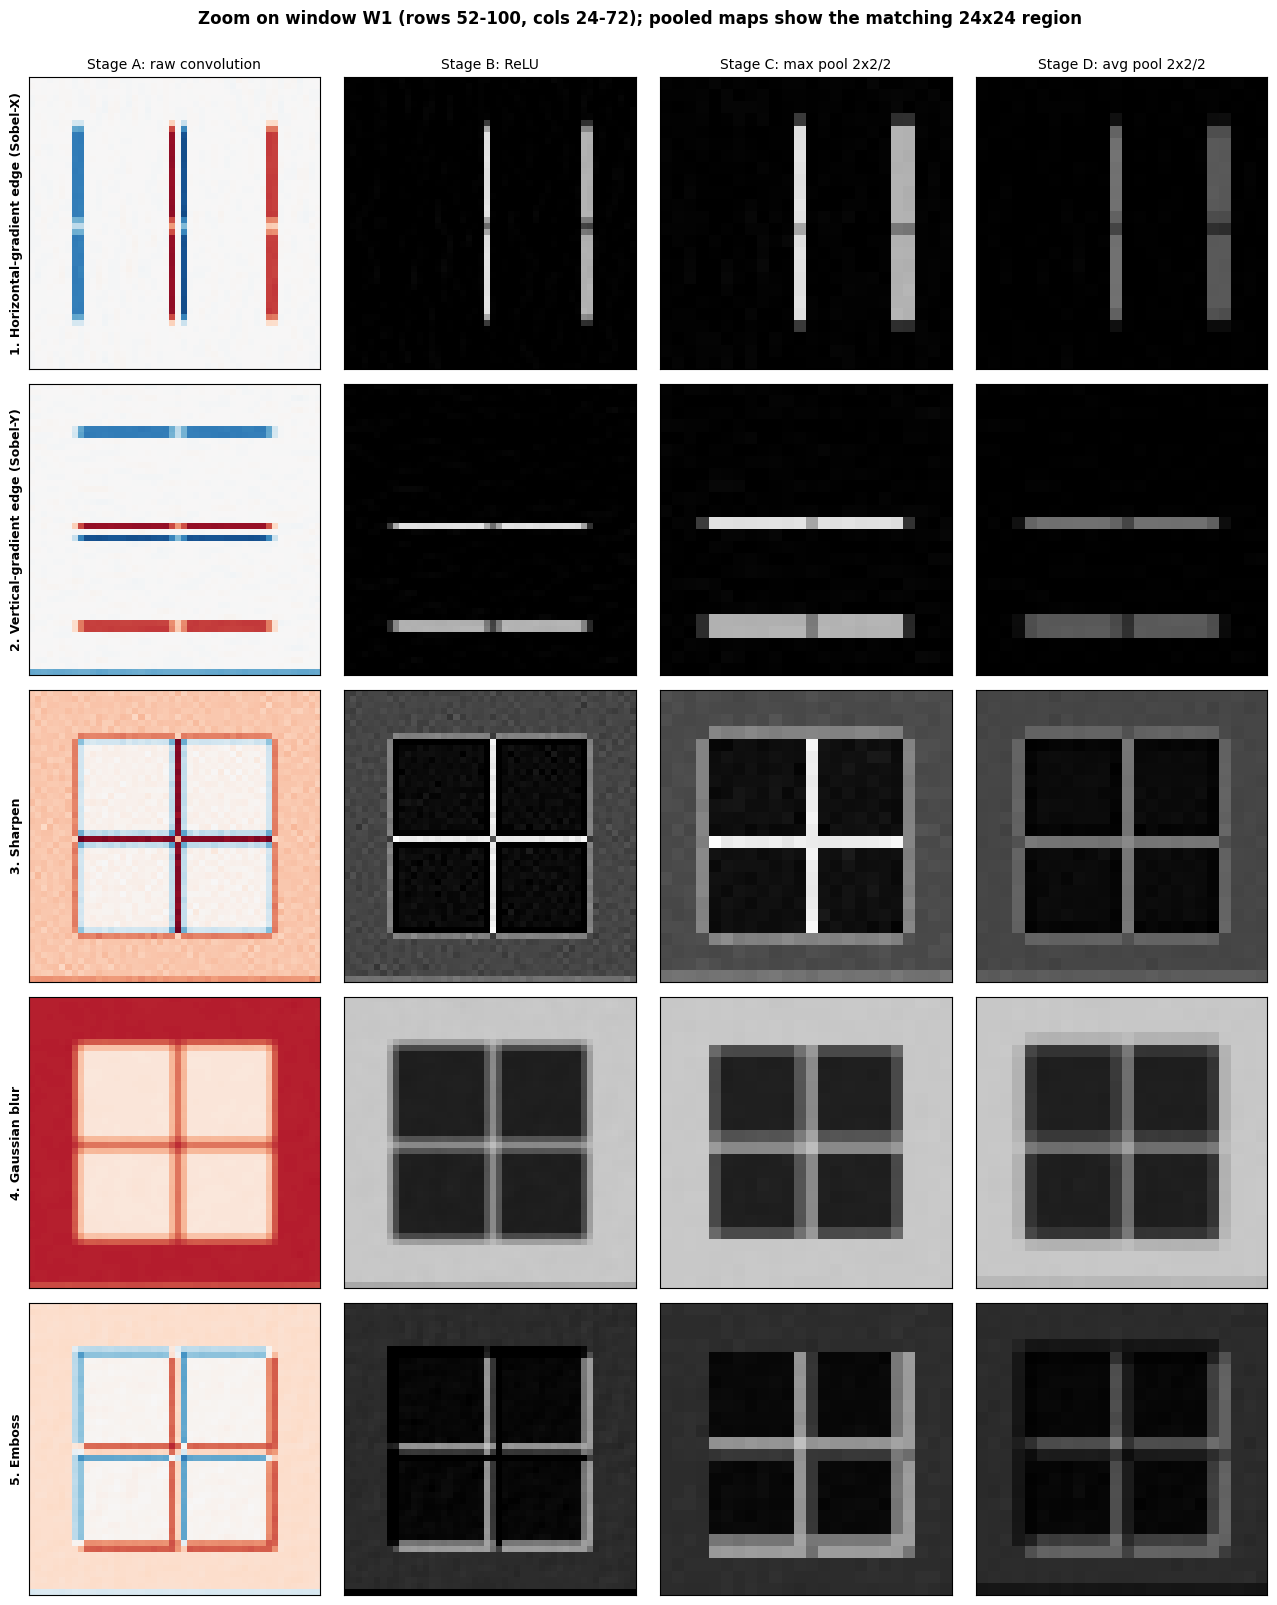

In [12]:
# Section 9b: Zoomed feature maps around window W1, pixel by pixel
r0, r1, c0, c1 = 52, 100, 24, 72          # 48 x 48 crop in full resolution
fig, axes = plt.subplots(5, 4, figsize=(13, 16))
for r, (key, st) in enumerate(results.items()):
    a_lim = np.abs(st['A']).max(); b_max = st['B'].max()
    crops = {'A': st['A'][r0:r1, c0:c1], 'B': st['B'][r0:r1, c0:c1],
             'C': st['C'][r0 // 2:r1 // 2, c0 // 2:c1 // 2], 'D': st['D'][r0 // 2:r1 // 2, c0 // 2:c1 // 2]}
    for c, s in enumerate('ABCD'):
        ax = axes[r, c]
        kw = dict(cmap='RdBu_r', vmin=-a_lim, vmax=a_lim) if s == 'A' else dict(cmap='gray', vmin=0, vmax=b_max)
        ax.imshow(crops[s], interpolation='nearest', **kw)
        ax.set_xticks([]); ax.set_yticks([])
        if r == 0: ax.set_title(STAGE_TITLES[s])
        if c == 0: ax.set_ylabel(FILTERS[key]['name'], fontsize=9, weight='bold')
plt.suptitle(f'Zoom on window W1 (rows {r0}-{r1}, cols {c0}-{c1}); pooled maps show the matching 24x24 region',
             y=1.0, weight='bold')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/fig3_zoom_window_W1.png')
plt.show()

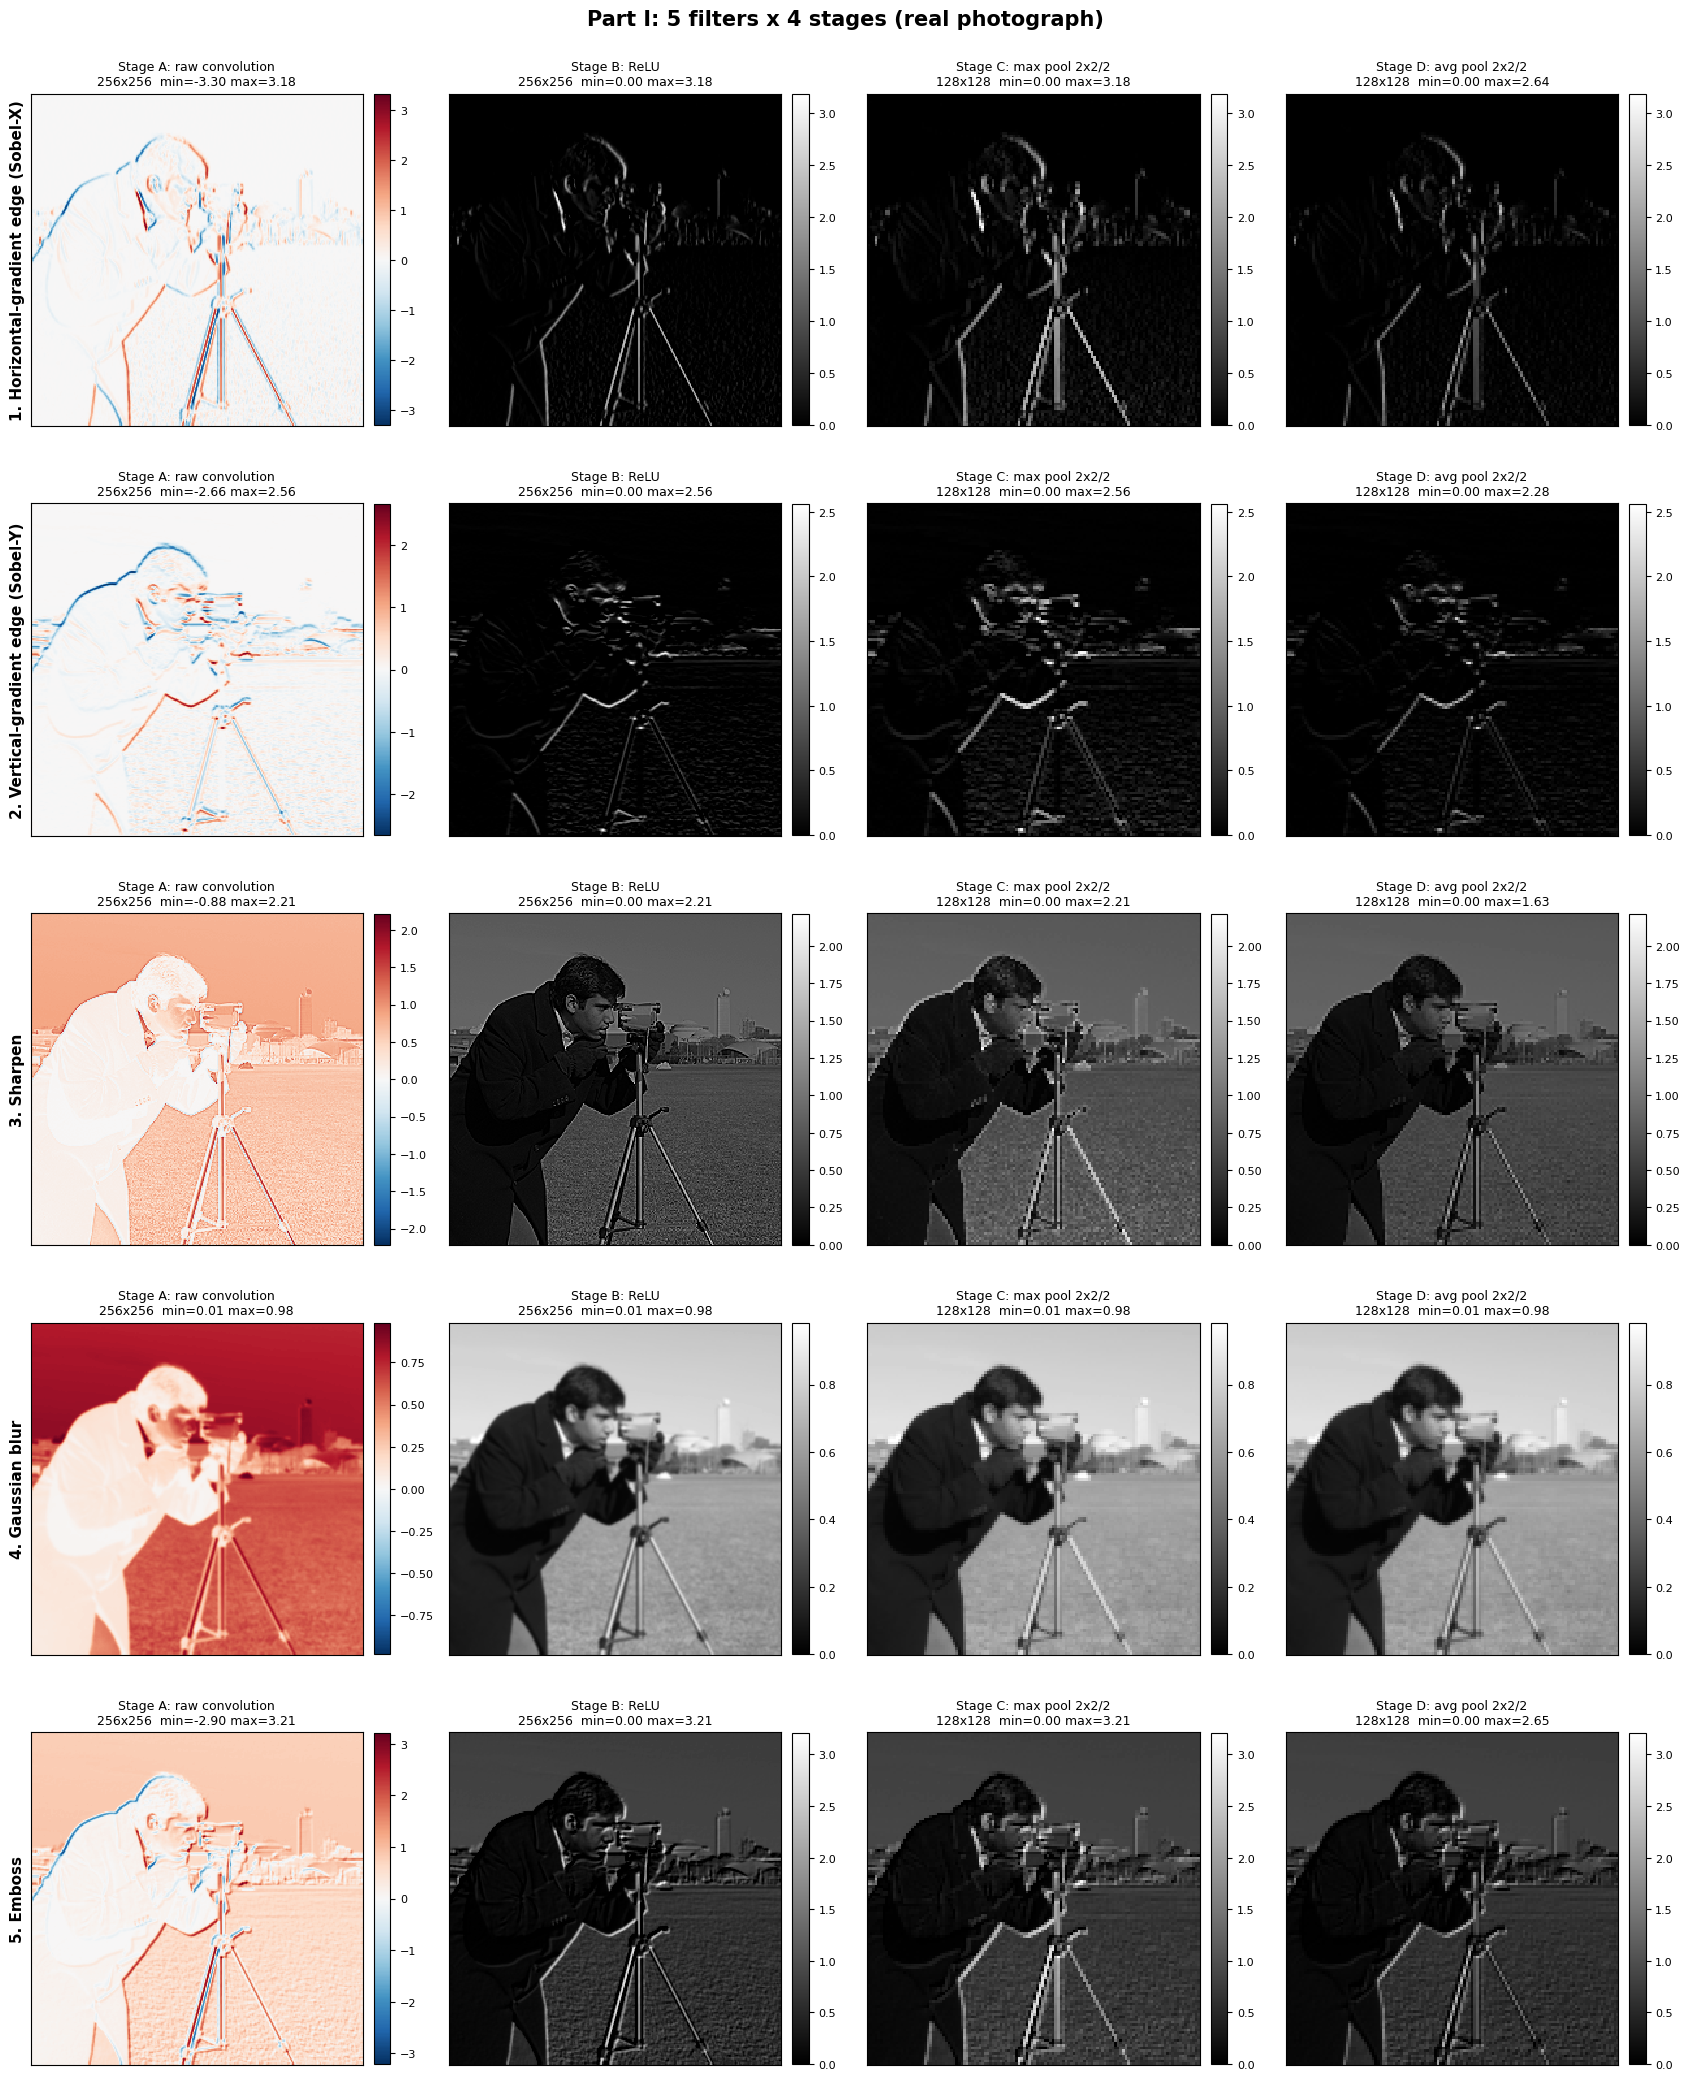

In [13]:
# Section 9c: Same pipeline on a real photograph (sanity check)
plot_grid(results_photo, 'Part I: 5 filters x 4 stages (real photograph)', 'fig4_grid_5x4_real_photo.png')

In [14]:
# Section 10: Model A (standard 3x3 kernels, max pooling)
INPUT_SHAPE = (32, 32, 3)
NUM_CLASSES = 10

def build_model(kernel_size, pool, name, padding='valid', pool_after='conv2'):
    """Conv1(5) -> Conv2(10) -> Pool 2x2/2 -> GlobalAveragePooling -> Dense(10).
    pool_after lets us move the pooling layer to prove it does not change the parameter count."""
    Pool = layers.MaxPooling2D if pool == 'max' else layers.AveragePooling2D
    net = [keras.Input(shape=INPUT_SHAPE, name='input_rgb'),
           layers.Conv2D(5, kernel_size, padding=padding, activation='relu', name='conv1')]
    if pool_after == 'conv1':
        net.append(Pool(pool_size=2, strides=2, name=f'{pool}_pool'))
    net.append(layers.Conv2D(10, kernel_size, padding=padding, activation='relu', name='conv2'))
    if pool_after == 'conv2':
        net.append(Pool(pool_size=2, strides=2, name=f'{pool}_pool'))
    net += [layers.GlobalAveragePooling2D(name='gap'),
            layers.Dense(NUM_CLASSES, activation='softmax', name='dense_out')]
    return keras.Sequential(net, name=name)

model_a = build_model(3, 'max', 'Model_A_standard_3x3')
print("Model A built. Layers:", [l.name for l in model_a.layers])

Model A built. Layers: ['conv1', 'conv2', 'max_pool', 'gap', 'dense_out']


In [15]:
# Section 11: Model B (large 5x5 kernels, average pooling)
model_b = build_model(5, 'avg', 'Model_B_large_5x5')
print("Model B built. Layers:", [l.name for l in model_b.layers])

# Shape check: push one fake image through both models
dummy = tf.zeros((1,) + INPUT_SHAPE)
for m in (model_a, model_b):
    x = dummy
    print(f"\n{m.name}")
    for lyr in m.layers:
        x = lyr(x)
        print(f"  {lyr.name:10s} -> {tuple(x.shape)}")
    assert tuple(x.shape) == (1, NUM_CLASSES)

Model B built. Layers: ['conv1', 'conv2', 'avg_pool', 'gap', 'dense_out']

Model_A_standard_3x3
  conv1      -> (1, 30, 30, 5)
  conv2      -> (1, 28, 28, 10)
  max_pool   -> (1, 14, 14, 10)
  gap        -> (1, 10)
  dense_out  -> (1, 10)

Model_B_large_5x5
  conv1      -> (1, 28, 28, 5)
  conv2      -> (1, 24, 24, 10)
  avg_pool   -> (1, 12, 12, 10)
  gap        -> (1, 10)
  dense_out  -> (1, 10)


In [16]:
# Section 12: Manual parameter calculation (done BEFORE looking at model.summary())
def conv_params(kh, kw, cin, cout):
    """(Kh * Kw * Cin + 1) * Cout : weights of each filter + 1 bias, times the number of filters."""
    return (kh * kw * cin + 1) * cout

def dense_params(n_in, n_out):
    """(n_in + 1) * n_out : one weight per input per output neuron, + 1 bias per output neuron."""
    return (n_in + 1) * n_out

def manual_audit(k, label):
    rows = [
        ('conv1', f"({k}x{k}x3 + 1) x 5",   f"({k*k*3} + 1) x 5 = {k*k*3+1} x 5",    conv_params(k, k, 3, 5)),
        ('conv2', f"({k}x{k}x5 + 1) x 10",  f"({k*k*5} + 1) x 10 = {k*k*5+1} x 10",  conv_params(k, k, 5, 10)),
        ('pool',  "no weights",             "0",                                     0),
        ('gap',   "no weights",             "0",                                     0),
        ('dense_out', "(10 + 1) x 10",      "11 x 10",                               dense_params(10, 10)),
    ]
    print(f"\n{label}  (kernel {k}x{k})")
    print("-" * 72)
    for name, formula, step, val in rows:
        print(f"  {name:10s} {formula:22s} = {step:26s} = {val:5d}")
    total = sum(r[3] for r in rows)
    print("-" * 72)
    print(f"  TOTAL trainable parameters = {' + '.join(str(r[3]) for r in rows)} = {total}")
    return {r[0]: r[3] for r in rows}, total

manual_a, total_a_manual = manual_audit(3, "MODEL A")
manual_b, total_b_manual = manual_audit(5, "MODEL B")

# Why does Dense have 10 inputs? GAP turns the last feature map (h x w x 10) into ONE number per channel.
print("\nDense input size = number of channels after GAP = 10 (independent of the 28x28 or 24x24 spatial size).")


MODEL A  (kernel 3x3)
------------------------------------------------------------------------
  conv1      (3x3x3 + 1) x 5        = (27 + 1) x 5 = 28 x 5      =   140
  conv2      (3x3x5 + 1) x 10       = (45 + 1) x 10 = 46 x 10    =   460
  pool       no weights             = 0                          =     0
  gap        no weights             = 0                          =     0
  dense_out  (10 + 1) x 10          = 11 x 10                    =   110
------------------------------------------------------------------------
  TOTAL trainable parameters = 140 + 460 + 0 + 0 + 110 = 710

MODEL B  (kernel 5x5)
------------------------------------------------------------------------
  conv1      (5x5x3 + 1) x 5        = (75 + 1) x 5 = 76 x 5      =   380
  conv2      (5x5x5 + 1) x 10       = (125 + 1) x 10 = 126 x 10  =  1260
  pool       no weights             = 0                          =     0
  gap        no weights             = 0                          =     0
  dense_out  (10 

In [17]:
# Section 13: Framework summaries (the "Code Output" column)
model_a.summary()
model_b.summary()

# Also save the summaries as text for your report
with open(f'{FIG_DIR}/model_summaries.txt', 'w') as fh:
    for m in (model_a, model_b):
        m.summary(print_fn=lambda line, **kw: fh.write(line + '\n'))
        fh.write('\n')

Model: "Model_A_standard_3x3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 30, 30, 5)      │           140 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 28, 28, 10)     │           460 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pool (MaxPooling2D)         │ (None, 14, 14, 10)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 10)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_out (Dense)               │ (None, 10)             │           110 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 710 (2.77 KB)

 Trainable params: 710 (2.77 KB)

 Non-trainable params: 0 (0.00 B)

Model: "Model_B_large_5x5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 28, 28, 5)      │           380 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 24, 24, 10)     │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ avg_pool (AveragePooling2D)     │ (None, 12, 12, 10)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 10)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_out (Dense)               │ (None, 10)             │           110 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,750 (6.84 KB)

 Trainable params: 1,750 (6.84 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
# Section 14a: Manual vs framework, layer by layer
def framework_counts(model):
    out = {}
    for lyr in model.layers:
        key = 'pool' if 'pool' in lyr.name and lyr.name != 'gap' else lyr.name
        out[key] = int(sum(np.prod(w.shape) for w in lyr.trainable_weights))
    return out

rows = []
for label, model, manual in [('Model A', model_a, manual_a), ('Model B', model_b, manual_b)]:
    fw = framework_counts(model)
    for layer_name, m_val in manual.items():
        rows.append({'model': label, 'layer': layer_name, 'manual': m_val,
                     'keras': fw[layer_name], 'match': m_val == fw[layer_name]})
    total_fw = int(sum(np.prod(w.shape) for w in model.trainable_weights))
    rows.append({'model': label, 'layer': 'TOTAL', 'manual': sum(manual.values()),
                 'keras': total_fw, 'match': sum(manual.values()) == total_fw})
audit = pd.DataFrame(rows)
assert audit['match'].all(), "Manual count does not match Keras!"
total_a = model_a.count_params(); total_b = model_b.count_params()
assert (total_a, total_b) == (total_a_manual, total_b_manual)
print("All manual counts match Keras exactly.\n")
audit

All manual counts match Keras exactly.



,model,layer,manual,keras,match
0,Model A,conv1,140,140,True
1,Model A,conv2,460,460,True
2,Model A,pool,0,0,True
3,Model A,gap,0,0,True
4,Model A,dense_out,110,110,True
5,Model A,TOTAL,710,710,True
6,Model B,conv1,380,380,True
7,Model B,conv2,1260,1260,True
8,Model B,pool,0,0,True
9,Model B,gap,0,0,True


In [19]:
# Section 14b: Do padding or pooling position change the count? (They should not.)
variants = []
for k, pool in [(3, 'max'), (5, 'avg')]:
    for padding in ['valid', 'same']:
        for pool_after in ['conv1', 'conv2']:
            m = build_model(k, pool, f'v_{k}_{padding}_{pool_after}', padding, pool_after)
            variants.append({'kernel': f'{k}x{k}', 'padding': padding, 'pool after': pool_after,
                             'map entering GAP': tuple(m.get_layer('gap').input.shape[1:]),
                             'trainable params': m.count_params()})
variants = pd.DataFrame(variants)
print(variants.to_string(index=False))
print("\nSpatial sizes change, parameter counts do not: weights depend only on kernel size and channels.")

kernel padding pool after map entering GAP  trainable params
   3x3   valid      conv1     (13, 13, 10)               710
   3x3   valid      conv2     (14, 14, 10)               710
   3x3    same      conv1     (16, 16, 10)               710
   3x3    same      conv2     (16, 16, 10)               710
   5x5   valid      conv1     (10, 10, 10)              1750
   5x5   valid      conv2     (12, 12, 10)              1750
   5x5    same      conv1     (16, 16, 10)              1750
   5x5    same      conv2     (16, 16, 10)              1750

Spatial sizes change, parameter counts do not: weights depend only on kernel size and channels.


Total params : A = 710, B = 1750
Increase     : (1750 - 710) / 710 x 100 = 1040 / 710 x 100 = 146.4789 %
Model B is 2.4648 times the size of Model A

Conv layers only: A = 600, B = 1640, increase = 1040/600 = 173.3333 %
Pure weight ratio per conv layer (bias ignored): 25/9 = 2.7778  ->  +177.78 %


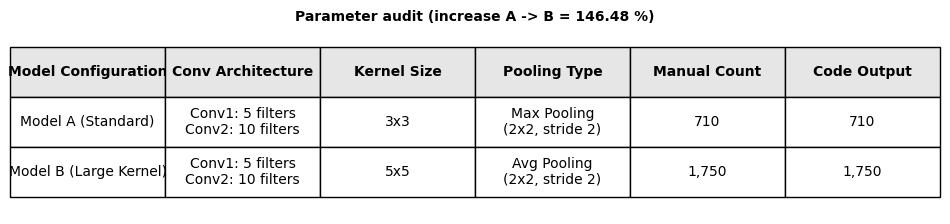

In [20]:
# Section 14c: Exact percentage increase and the audit table figure
increase_total = (total_b - total_a) / total_a * 100
conv_a = manual_a['conv1'] + manual_a['conv2']
conv_b = manual_b['conv1'] + manual_b['conv2']
increase_conv = (conv_b - conv_a) / conv_a * 100

print(f"Total params : A = {total_a}, B = {total_b}")
print(f"Increase     : ({total_b} - {total_a}) / {total_a} x 100 = {total_b - total_a} / {total_a} x 100 = {increase_total:.4f} %")
print(f"Model B is {total_b / total_a:.4f} times the size of Model A")
print(f"\nConv layers only: A = {conv_a}, B = {conv_b}, increase = {conv_b - conv_a}/{conv_a} = {increase_conv:.4f} %")
print(f"Pure weight ratio per conv layer (bias ignored): 25/9 = {25/9:.4f}  ->  +{(25/9 - 1)*100:.2f} %")

# Audit table in the same layout as the assignment PDF
table = [['Model A (Standard)', 'Conv1: 5 filters\nConv2: 10 filters', '3x3', 'Max Pooling\n(2x2, stride 2)',
          f"{total_a_manual:,}", f"{total_a:,}"],
         ['Model B (Large Kernel)', 'Conv1: 5 filters\nConv2: 10 filters', '5x5', 'Avg Pooling\n(2x2, stride 2)',
          f"{total_b_manual:,}", f"{total_b:,}"]]
fig, ax = plt.subplots(figsize=(12, 2.4)); ax.axis('off')
tb = ax.table(cellText=table, colLabels=['Model Configuration', 'Conv Architecture', 'Kernel Size',
                                         'Pooling Type', 'Manual Count', 'Code Output'],
              loc='center', cellLoc='center')
tb.auto_set_font_size(False); tb.set_fontsize(10); tb.scale(1, 3.0)
for (r, c), cell in tb.get_celld().items():
    if r == 0: cell.set_text_props(weight='bold'); cell.set_facecolor('#e6e6e6')
ax.set_title(f"Parameter audit (increase A -> B = {increase_total:.2f} %)", weight='bold')
plt.savefig(f'{FIG_DIR}/fig5_parameter_audit_table.png')
plt.show()

Model A:
   layer  kernel  stride receptive field  jump
   conv1       3       1             3x3     1
   conv2       3       1             5x5     1
max_pool       2       2             6x6     2

Model B:
   layer  kernel  stride receptive field  jump
   conv1       5       1             5x5     1
   conv2       5       1             9x9     1
avg_pool       2       2           10x10     2

One 5x5 conv vs two stacked 3x3 convs:
     layer  kernel  stride receptive field  jump
single 5x5       5       1             5x5     1
 layer  kernel  stride receptive field  jump
3x3 #1       3       1             3x3     1
3x3 #2       3       1             5x5     1
one 5x5 conv            : measured receptive field 5x5
two stacked 3x3 convs   : measured receptive field 5x5
Model A conv1+conv2     : measured receptive field 5x5
Model B conv1+conv2     : measured receptive field 9x9


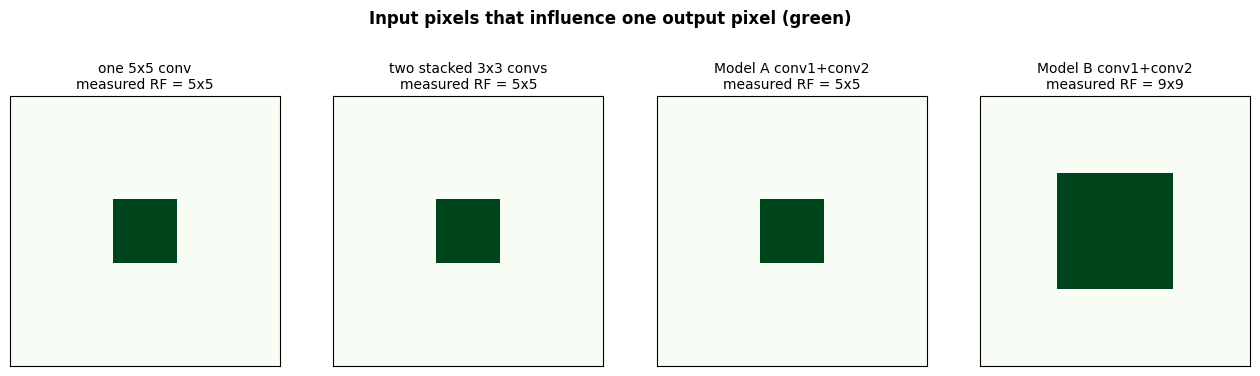

In [21]:
# Section 15: Receptive field (RF) comparison
def receptive_field(layer_specs):
    """layer_specs: list of (name, kernel, stride). Standard recurrence:
       RF_new = RF_old + (k - 1) * jump,   jump_new = jump_old * stride
    'jump' is how many input pixels one step in the current map corresponds to."""
    rf, jump, rows = 1, 1, []
    for name, k, s in layer_specs:
        rf = rf + (k - 1) * jump
        jump = jump * s
        rows.append({'layer': name, 'kernel': k, 'stride': s, 'receptive field': f"{rf}x{rf}", 'jump': jump})
    return pd.DataFrame(rows)

print("Model A:"); print(receptive_field([('conv1', 3, 1), ('conv2', 3, 1), ('max_pool', 2, 2)]).to_string(index=False))
print("\nModel B:"); print(receptive_field([('conv1', 5, 1), ('conv2', 5, 1), ('avg_pool', 2, 2)]).to_string(index=False))
print("\nOne 5x5 conv vs two stacked 3x3 convs:")
print(receptive_field([('single 5x5', 5, 1)]).to_string(index=False))
print(receptive_field([('3x3 #1', 3, 1), ('3x3 #2', 3, 1)]).to_string(index=False))

def empirical_rf(conv_stack, in_ch):
    """Measure the RF directly: which input pixels change the centre output pixel?
    We take the gradient of the centre output w.r.t. the input and count non-zero pixels."""
    x = tf.random.normal((1, 21, 21, in_ch), seed=SEED)
    with tf.GradientTape() as tape:
        tape.watch(x)
        y = conv_stack(x)
        cy, cx = y.shape[1] // 2, y.shape[2] // 2
        target = tf.reduce_sum(y[0, cy, cx, :])
    g = tf.reduce_sum(tf.abs(tape.gradient(target, x)[0]), axis=-1).numpy()
    rows_nz, cols_nz = np.nonzero(g > 0)
    return rows_nz.max() - rows_nz.min() + 1, cols_nz.max() - cols_nz.min() + 1, g

linear = dict(padding='same', use_bias=False, kernel_initializer=keras.initializers.RandomNormal(seed=SEED))
one_5x5 = keras.Sequential([layers.Conv2D(10, 5, **linear)])
two_3x3 = keras.Sequential([layers.Conv2D(10, 3, **linear), layers.Conv2D(10, 3, **linear)])
def linear_copy(model):
    # same kernels as the real model, ReLU removed so no gradient path is switched off
    stack = keras.Sequential([keras.Input((None, None, 3))] +
                             [layers.Conv2D(model.get_layer(n).filters, model.get_layer(n).kernel_size, name=n)
                              for n in ('conv1', 'conv2')])
    for n in ('conv1', 'conv2'):
        stack.get_layer(n).set_weights(model.get_layer(n).get_weights())
    return stack
convs_a, convs_b = linear_copy(model_a), linear_copy(model_b)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (title, stack, ch) in zip(axes, [('one 5x5 conv', one_5x5, 10), ('two stacked 3x3 convs', two_3x3, 10),
                                          ('Model A conv1+conv2', convs_a, 3), ('Model B conv1+conv2', convs_b, 3)]):
    h, w, g = empirical_rf(stack, ch)
    ax.imshow(g > 0, cmap='Greens', interpolation='nearest')
    ax.set_title(f"{title}\nmeasured RF = {h}x{w}")
    ax.set_xticks([]); ax.set_yticks([])
    print(f"{title:24s}: measured receptive field {h}x{w}")
plt.suptitle('Input pixels that influence one output pixel (green)', weight='bold', y=1.05)
plt.savefig(f'{FIG_DIR}/fig6_receptive_fields.png')
plt.show()

 filter                                             location   raw A    ReLU  Leaky 0.1  Sigmoid
Sobel-X   col 31-32: wall -> glass (left edge)  [r=70, c=32]  -2.611   0.000     -0.261    0.068
Sobel-X               col 47: glass -> mullion  [r=70, c=47]   3.330   3.330      3.330    0.965
Sobel-X               col 49: mullion -> glass  [r=70, c=49]  -3.301   0.000     -0.330    0.036
Sobel-X  col 63-64: glass -> wall (right edge)  [r=70, c=64]   2.596   2.596      2.596    0.931
Sobel-Y    row 59-60: wall -> glass (top edge)  [r=60, c=40]  -2.659   0.000     -0.266    0.065
Sobel-Y               row 75: glass -> mullion  [r=75, c=40]   3.311   3.311      3.311    0.965
Sobel-Y               row 77: mullion -> glass  [r=77, c=40]  -3.346   0.000     -0.335    0.034
Sobel-Y row 91-92: glass -> wall (bottom edge)  [r=92, c=40]   2.620   2.620      2.620    0.932
Sobel-Y row 100: wall -> ledge (top of ledge)  [r=100, c=40]  -1.954   0.000     -0.195    0.124
Sobel-Y            row 102-103

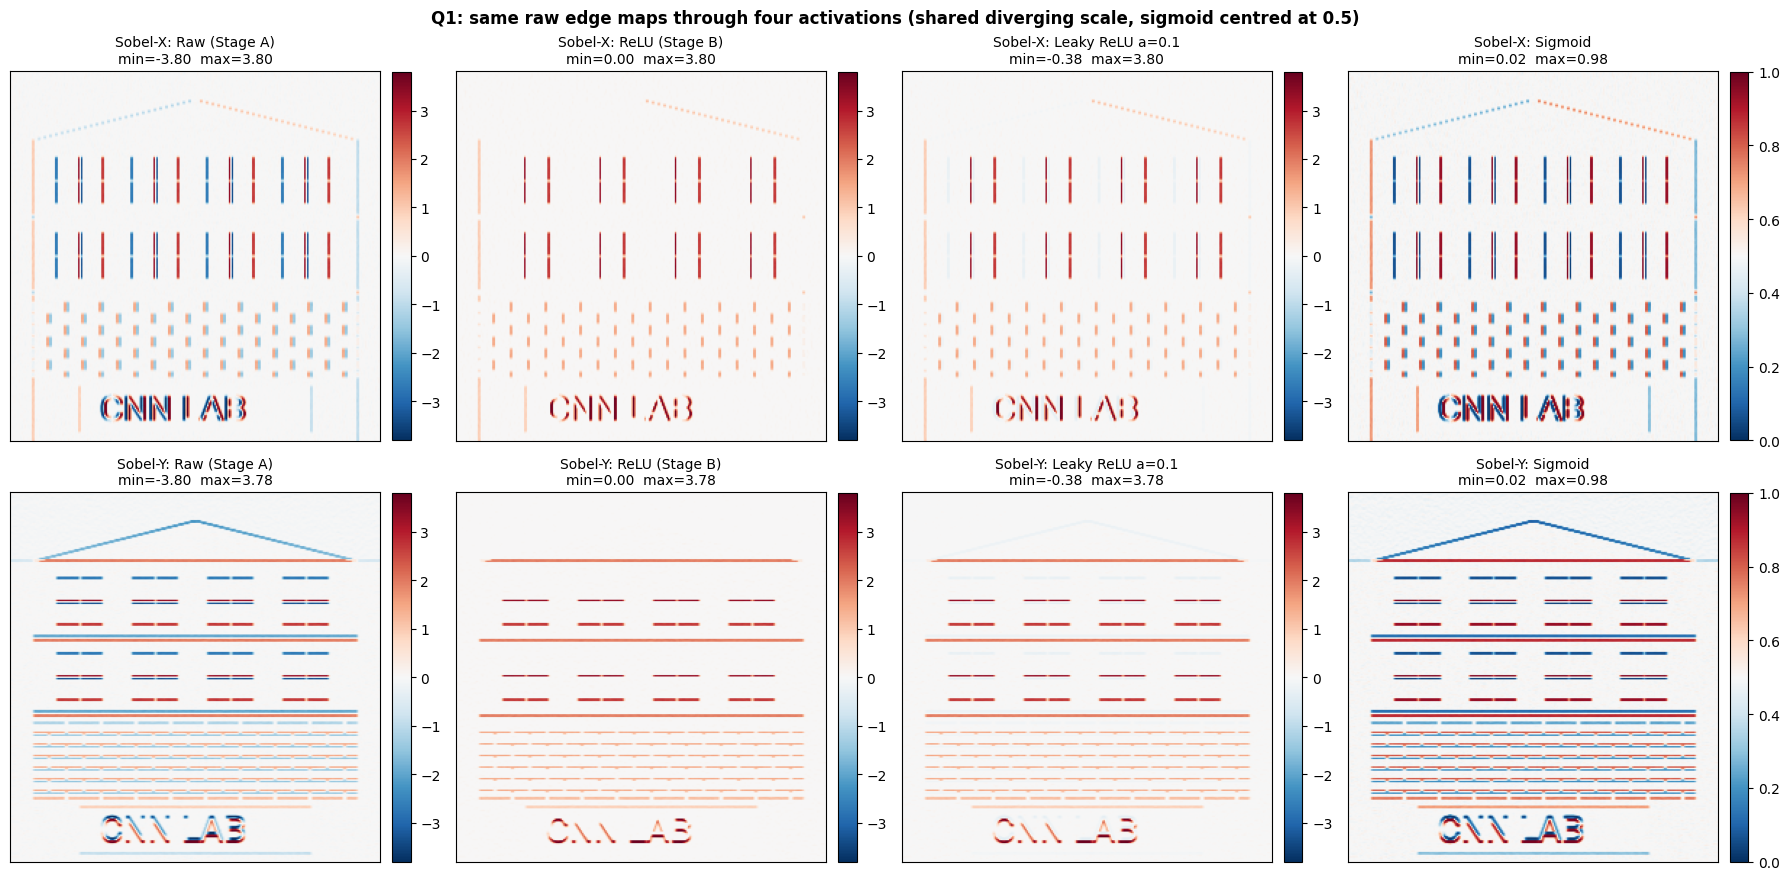

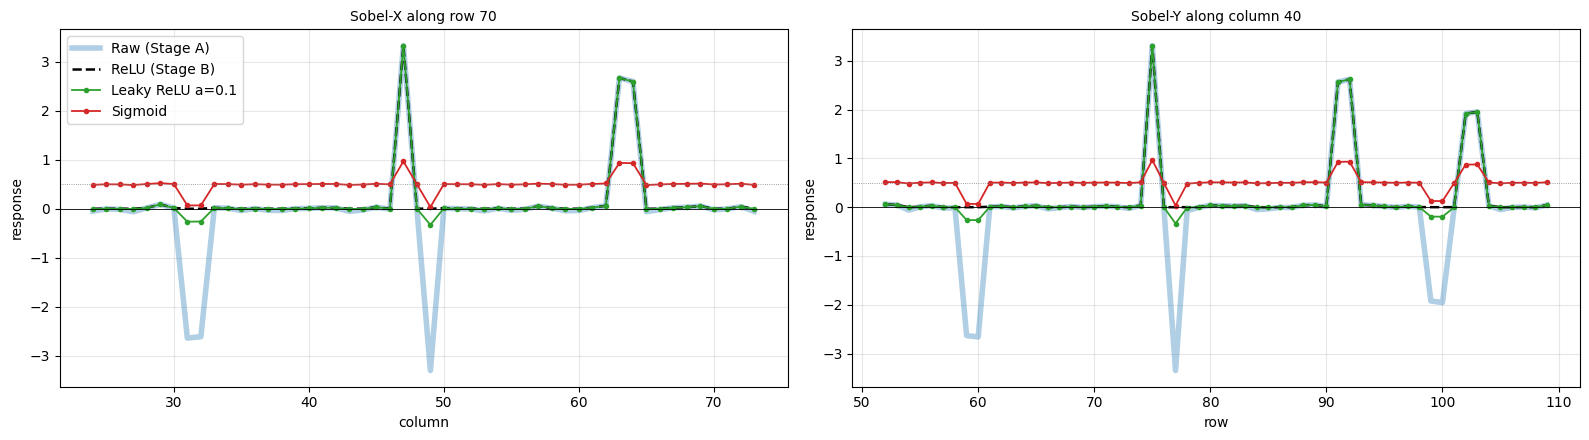

In [22]:
# Q1: ReLU "blackout" on the two edge rows, and the alternatives
def leaky_relu(x, alpha=0.1):
    return np.where(x > 0, x, alpha * x)

def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))

ACTS = {'Raw (Stage A)': lambda x: x, 'ReLU (Stage B)': relu,
        'Leaky ReLU a=0.1': leaky_relu, 'Sigmoid': sigmoid}

# 1) Exact pixel values across window W1 (row 70 for Sobel-X, column 40 for Sobel-Y)
A_x, A_y = results['sobel_x']['A'], results['sobel_y']['A']
probe_x = {'col 31-32: wall -> glass (left edge)': (70, 32), 'col 47: glass -> mullion': (70, 47),
           'col 49: mullion -> glass': (70, 49), 'col 63-64: glass -> wall (right edge)': (70, 64)}
probe_y = {'row 59-60: wall -> glass (top edge)': (60, 40), 'row 75: glass -> mullion': (75, 40),
           'row 77: mullion -> glass': (77, 40), 'row 91-92: glass -> wall (bottom edge)': (92, 40),
           'row 100: wall -> ledge (top of ledge)': (100, 40), 'row 102-103: ledge -> wall': (103, 40)}
rows = []
for fname, A, probes in [('Sobel-X', A_x, probe_x), ('Sobel-Y', A_y, probe_y)]:
    for label, (r, c) in probes.items():
        v = A[r, c]
        rows.append({'filter': fname, 'location': f"{label}  [r={r}, c={c}]", 'raw A': float(v),
                     'ReLU': float(relu(v)), 'Leaky 0.1': float(leaky_relu(v)), 'Sigmoid': float(sigmoid(v))})
q1_pixels = pd.DataFrame(rows)
print(q1_pixels.to_string(index=False, float_format=lambda v: f"{v:7.3f}"))

# 2) How much edge information did ReLU throw away?
for fname, A in [('Sobel-X', A_x), ('Sobel-Y', A_y)]:
    strong = np.abs(A) > 0.5
    print(f"\n{fname}: {100 * (A[strong] < 0).mean():.1f}% of strong edge pixels (|A|>0.5) are negative "
          f"-> set to 0 by ReLU; {100 * np.abs(A[A < 0]).sum() / np.abs(A).sum():.1f}% of total |A| removed.")
roof = A_y[18:47, 16:240]
print(f"Roof slopes (rows 18-46): {100 * (roof[np.abs(roof) > 0.5] < 0).mean():.1f}% of strong Sobel-Y responses are "
      f"negative, so the sloped roof outline disappears after ReLU.")
print(f"Flat wall (rows 50-56, cols 20-230): Sigmoid output mean = {sigmoid(A_x[50:57, 20:230]).mean():.3f} "
      f"(sigmoid(0) = 0.5, so 'nothing here' becomes mid grey)")

# 3) Visual comparison of the 4 activation choices
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for r, (fname, A) in enumerate([('Sobel-X', A_x), ('Sobel-Y', A_y)]):
    lim = np.abs(A).max()
    for c, (aname, fn) in enumerate(ACTS.items()):
        out = fn(A); ax = axes[r, c]
        if aname == 'Sigmoid':
            im = ax.imshow(out, cmap='RdBu_r', vmin=0, vmax=1)
        else:
            im = ax.imshow(out, cmap='RdBu_r', vmin=-lim, vmax=lim)
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
        ax.set_title(f"{fname}: {aname}\nmin={out.min():.2f}  max={out.max():.2f}")
        ax.set_xticks([]); ax.set_yticks([])
plt.suptitle('Q1: same raw edge maps through four activations (shared diverging scale, sigmoid centred at 0.5)',
             weight='bold')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/fig7_q1_activations.png'); plt.show()

# 4) 1-D profiles: the clearest way to see what each activation does to an edge
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
cols = np.arange(24, 74); rws = np.arange(52, 110)
for ax, (fname, xs, prof, xl) in zip(axes, [('Sobel-X along row 70', cols, A_x[70, cols], 'column'),
                                           ('Sobel-Y along column 40', rws, A_y[rws, 40], 'row')]):
    styles = {'Raw (Stage A)': dict(color='tab:blue', lw=4, alpha=0.35),
              'ReLU (Stage B)': dict(color='black', lw=1.8, ls='--'),
              'Leaky ReLU a=0.1': dict(color='tab:green', lw=1.3, marker='.'),
              'Sigmoid': dict(color='tab:red', lw=1.3, marker='.')}
    for aname, fn in ACTS.items():
        ax.plot(xs, fn(prof), label=aname, **styles[aname])
    ax.axhline(0, color='k', lw=0.6); ax.axhline(0.5, color='grey', lw=0.6, ls=':')
    ax.set_title(fname); ax.set_xlabel(xl); ax.set_ylabel('response'); ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/fig8_q1_profiles.png'); plt.show()

                                        peak B  peak C (max)  peak D (avg)  mean D/C on strong cells  strong cells
filter                                                                                                            
1. Horizontal-gradient edge (Sobel-X)    3.802         3.802         3.645                     0.475          1096
2. Vertical-gradient edge (Sobel-Y)      3.781         3.781         3.452                     0.567          1779
3. Sharpen                               2.854         2.854         1.894                     0.855          9845
4. Gaussian blur                         1.000         1.000         1.000                     0.953         15223
5. Emboss                                4.541         4.541         3.757                     0.651          2990

Sharpen, Stage B, rows 70-71, cols 46-51 (mullion is column 48):
[[0.08 0.   2.6  0.   0.18 0.08]
 [0.13 0.   2.65 0.   0.06 0.12]]
2x2 window rows 70-71, cols 48-49 -> max = 2.65, avg = 1.31

S

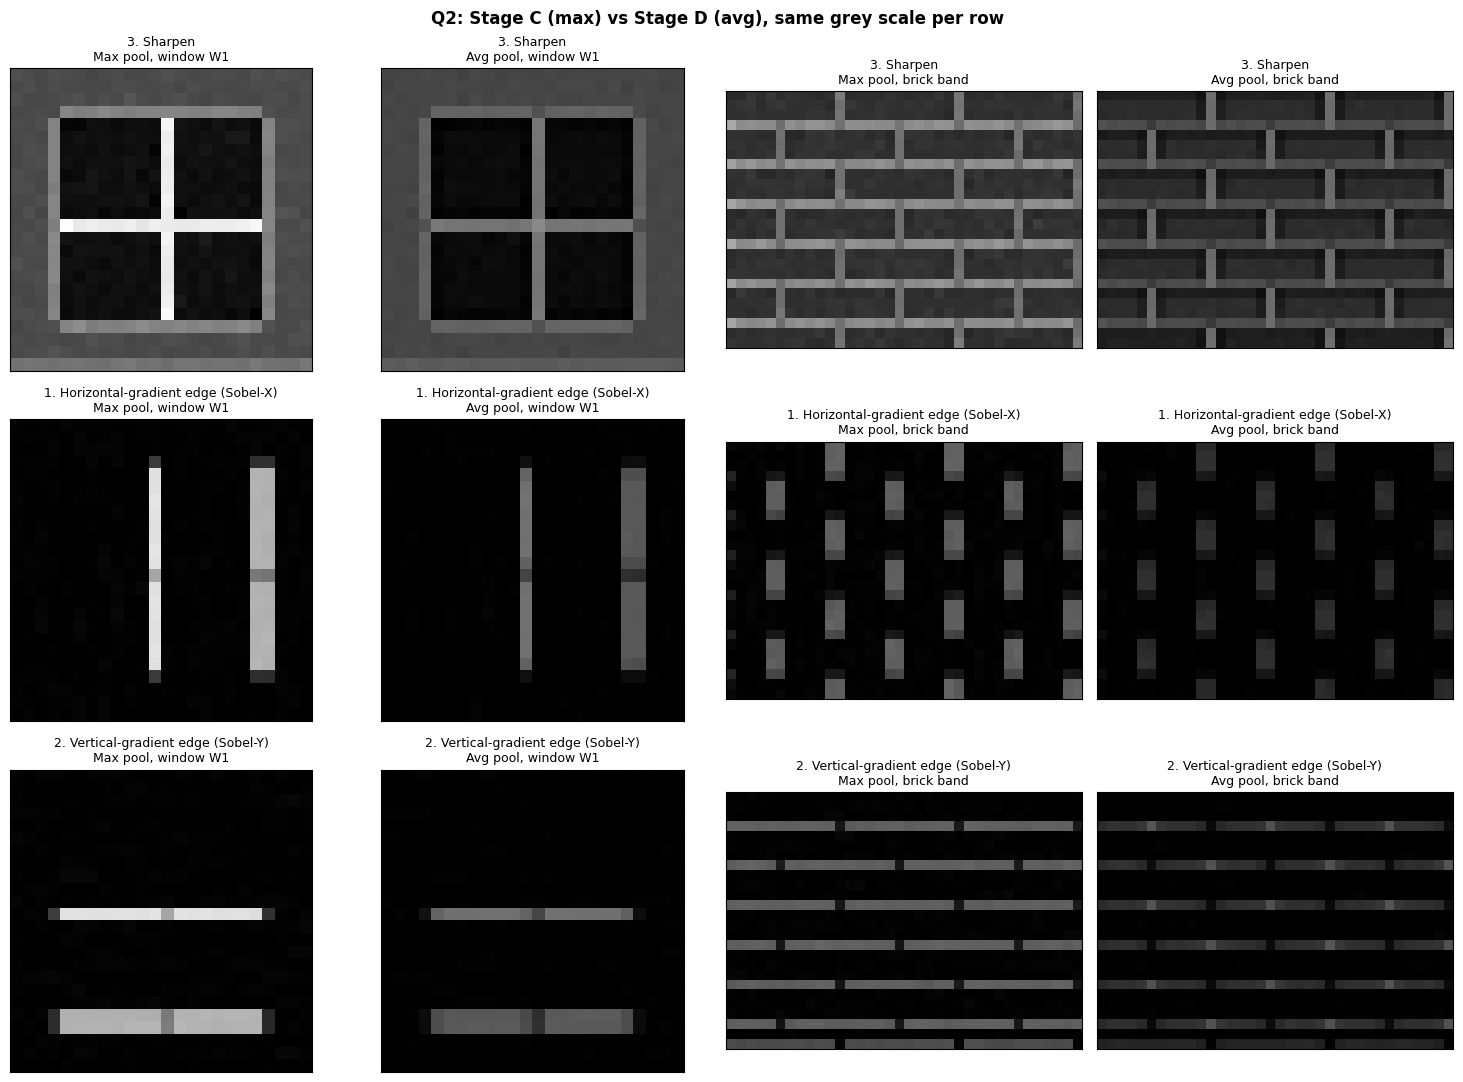

In [23]:
# Q2 (part 1): what max pooling keeps and average pooling washes out, on OUR feature maps
def pooling_retention(st):
    """For every pooled cell where max pooling found a strong feature (C > 25% of max B),
    how much of it survives average pooling? ratio = D / C.
    1.00 -> the feature filled the whole 2x2 window; 0.25 -> only one of four pixels was active."""
    C_, D_ = st['C'], st['D']
    strong = C_ > 0.25 * st['B'].max()
    return (D_[strong] / C_[strong]).mean(), strong.sum()

rows = []
for key in ['sobel_x', 'sobel_y', 'sharpen', 'blur', 'emboss']:
    st = results[key]; ratio, n = pooling_retention(st)
    rows.append({'filter': FILTERS[key]['name'], 'peak B': st['B'].max(), 'peak C (max)': st['C'].max(),
                 'peak D (avg)': st['D'].max(), 'mean D/C on strong cells': ratio, 'strong cells': n})
q2_table = pd.DataFrame(rows).set_index('filter')
print(q2_table.to_string(float_format=lambda v: f"{v:8.3f}"))

# The 1 px vertical mullion of window W1 (column 48) under the Sharpen filter
B = results['sharpen']['B']
print("\nSharpen, Stage B, rows 70-71, cols 46-51 (mullion is column 48):")
print(np.round(B[70:72, 46:52], 2))
print(f"2x2 window rows 70-71, cols 48-49 -> max = {pool2d(B, mode='max')[35, 24]:.2f}, "
      f"avg = {pool2d(B, mode='avg')[35, 24]:.2f}")

B = results['sobel_x']['B']
print("\nSobel-X, Stage B, row 70, cols 44-51 (glass -> mullion edge at col 47):", np.round(B[70, 44:52], 2))
print(f"Pooled cell covering cols 46-47 -> max = {results['sobel_x']['C'][35, 23]:.2f}, "
      f"avg = {results['sobel_x']['D'][35, 23]:.2f}")

# Side by side zoom on window W1 and the brick band
fig, axes = plt.subplots(3, 4, figsize=(15, 11))
for r, key in enumerate(['sharpen', 'sobel_x', 'sobel_y']):
    st = results[key]; vmax = st['B'].max()
    for c, (s, (pr0, pr1, pc0, pc1)) in enumerate([('C', (26, 50, 12, 36)), ('D', (26, 50, 12, 36)),
                                                   ('C', (80, 106, 8, 44)), ('D', (80, 106, 8, 44))]):
        ax = axes[r, c]
        ax.imshow(st[s][pr0:pr1, pc0:pc1], cmap='gray', vmin=0, vmax=vmax, interpolation='nearest')
        ax.set_title(f"{FILTERS[key]['name']}\n{'Max' if s == 'C' else 'Avg'} pool, "
                     f"{'window W1' if c < 2 else 'brick band'}", fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])
plt.suptitle('Q2: Stage C (max) vs Stage D (avg), same grey scale per row', weight='bold')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/fig9_q2_max_vs_avg.png'); plt.show()

Sign crop (32, 160), 574 ink pixels (11.2% of the crop)
                pooling     level  darkest value  pixels darker than 0.5  ink contrast (paper - darkest 5%)
                    max 1 (16x80)          0.059                      74                              0.640
                    max  2 (8x40)          0.704                       0                              0.000
                    avg 1 (16x80)          0.054                     135                              0.862
                    avg  2 (8x40)          0.142                      36                              0.579
                    min 1 (16x80)          0.035                     211                              0.934
                    min  2 (8x40)          0.035                      89                              0.935
invert -> max -> invert 1 (16x80)          0.035                     211                              0.934
invert -> max -> invert  2 (8x40)          0.035                      89        

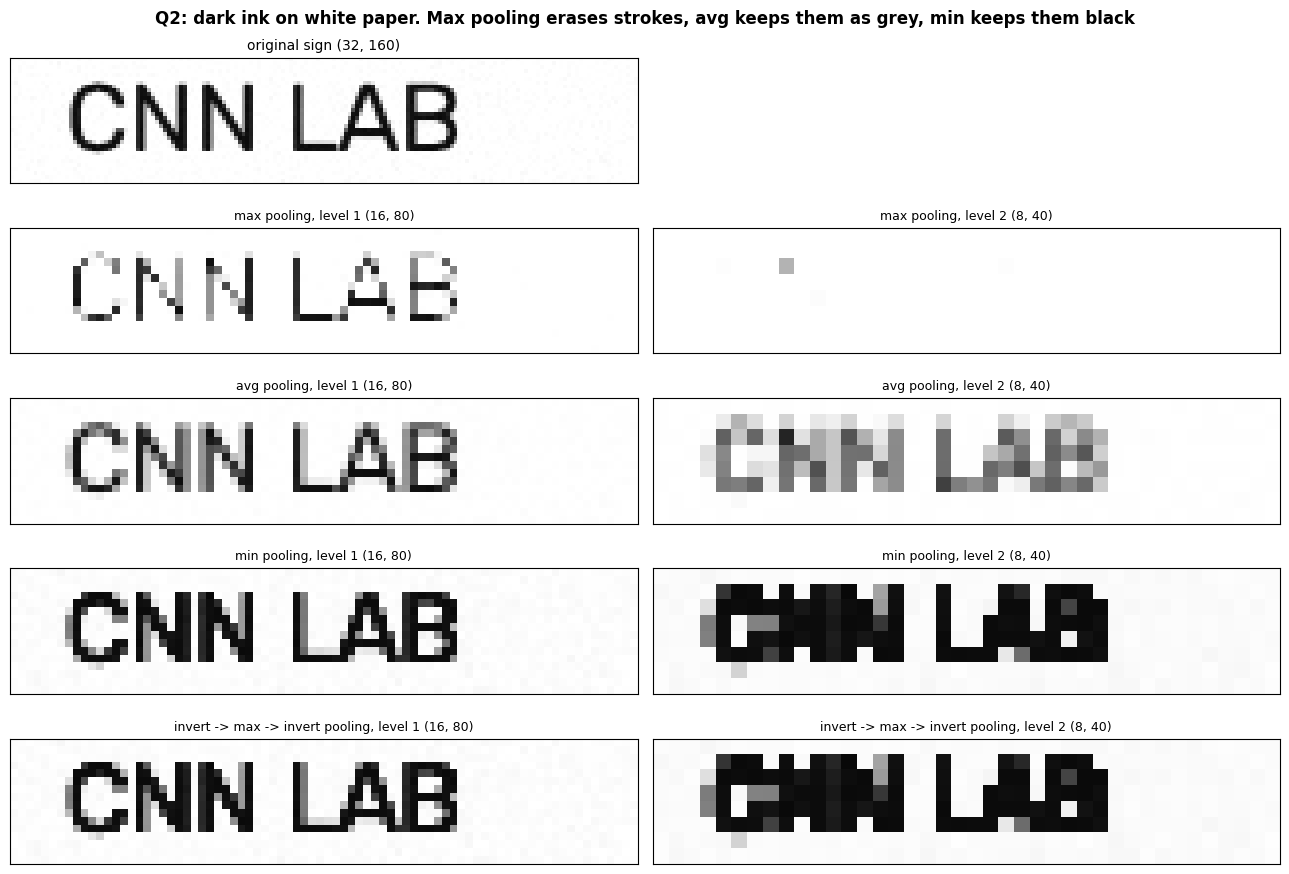

In [24]:
# Q2 (part 2): dark ink on a white background, using the sign from our own facade
r0, r1, c0, c1 = SIGN_BOX
sign = image[r0:r1, c0:c1]                 # raw pixels: ink about 0.06, paper about 1.0 (i.e. ~255)
ink_mask = sign < 0.5
print(f"Sign crop {sign.shape}, {ink_mask.sum()} ink pixels ({100 * ink_mask.mean():.1f}% of the crop)")

def pool_levels(x, mode, levels=2):
    outs = [x]
    for _ in range(levels):
        outs.append(pool2d(outs[-1], mode=mode))
    return outs

methods = {'max': pool_levels(sign, 'max'), 'avg': pool_levels(sign, 'avg'), 'min': pool_levels(sign, 'min'),
           'invert -> max -> invert': [1 - p for p in pool_levels(1 - sign, 'max')]}
rows = []
for name, outs in methods.items():
    for lvl in (1, 2):
        p = outs[lvl]
        rows.append({'pooling': name, 'level': f"{lvl} ({p.shape[0]}x{p.shape[1]})",
                     'darkest value': p.min(), 'pixels darker than 0.5': int((p < 0.5).sum()),
                     'ink contrast (paper - darkest 5%)': np.median(p) - np.percentile(p, 5)})
q2_ink = pd.DataFrame(rows)
print(q2_ink.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
assert np.allclose(methods['min'][2], methods['invert -> max -> invert'][2])

fig, axes = plt.subplots(5, 2, figsize=(13, 9))
axes[0, 0].imshow(sign, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
axes[0, 0].set_title(f'original sign {sign.shape}')
axes[0, 1].axis('off')
for r, (name, outs) in enumerate(methods.items(), start=1):
    for c, lvl in enumerate((1, 2)):
        ax = axes[r, c]
        ax.imshow(outs[lvl], cmap='gray', vmin=0, vmax=1, interpolation='nearest')
        ax.set_title(f"{name} pooling, level {lvl} {outs[lvl].shape}", fontsize=9)
for ax in axes.ravel(): ax.set_xticks([]); ax.set_yticks([])
plt.suptitle('Q2: dark ink on white paper. Max pooling erases strokes, avg keeps them as grey, min keeps them black',
             weight='bold')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/fig10_q2_ink_on_white.png'); plt.show()

In [25]:
# Q3: parameter explosion and receptive field equivalence (numbers)
print(f"Exact increase A -> B: (1750 - 710) / 710 = {increase_total:.4f} %  (conv layers only: {increase_conv:.4f} %)\n")

def single_5x5(cin, cout):
    return conv_params(5, 5, cin, cout)

def stacked_3x3(cin, cmid, cout):
    return conv_params(3, 3, cin, cmid) + conv_params(3, 3, cmid, cout)

cases = [
    ('General, C channels everywhere (C=10)', 10, 10, 10),
    ('Large layer, C=64 everywhere',          64, 64, 64),
    ('Model B conv2 (5 -> 10), middle = 5',    5,  5, 10),
    ('Model B conv2 (5 -> 10), middle = 10',   5, 10, 10),
    ('Model B conv1 (3 -> 5), middle = 5',     3,  5,  5),
]
rows = []
for label, cin, cmid, cout in cases:
    one, two = single_5x5(cin, cout), stacked_3x3(cin, cmid, cout)
    rows.append({'case (Cin, Cmid, Cout)': f"{label}", 'one 5x5': one, 'two 3x3': two,
                 'saved': one - two, 'saving %': 100 * (one - two) / one})
q3_table = pd.DataFrame(rows)
print(q3_table.to_string(index=False, float_format=lambda v: f"{v:.2f}"))

# Verify the C=10 case with real Keras layers
k5 = keras.Sequential([keras.Input((32, 32, 10)), layers.Conv2D(10, 5)])
k33 = keras.Sequential([keras.Input((32, 32, 10)), layers.Conv2D(10, 3), layers.Conv2D(10, 3)])
assert k5.count_params() == 2510 and k33.count_params() == 1820
print(f"\nKeras check (C=10): one 5x5 = {k5.count_params()}, two 3x3 = {k33.count_params()}")
print("Weights only, large C: 18C^2 vs 25C^2 -> saving tends to 7/25 = 28%")

Exact increase A -> B: (1750 - 710) / 710 = 146.4789 %  (conv layers only: 173.3333 %)

               case (Cin, Cmid, Cout)  one 5x5  two 3x3  saved  saving %
General, C channels everywhere (C=10)     2510     1820    690     27.49
         Large layer, C=64 everywhere   102464    73856  28608     27.92
  Model B conv2 (5 -> 10), middle = 5     1260      690    570     45.24
 Model B conv2 (5 -> 10), middle = 10     1260     1370   -110     -8.73
   Model B conv1 (3 -> 5), middle = 5      380      370     10      2.63

Keras check (C=10): one 5x5 = 2510, two 3x3 = 1820
Weights only, large C: 18C^2 vs 25C^2 -> saving tends to 7/25 = 28%


In [26]:
# Q4: does Conv -> ReLU -> MaxPool equal Conv -> MaxPool -> ReLU?
patches = {
    'all negative': np.array([[-3.0, -1.0], [-5.0, -2.0]]),
    'mixed signs':  np.array([[-3.0,  2.0], [-5.0,  1.0]]),
    'one positive': np.array([[-4.0, -2.0], [ 0.5, -6.0]]),
}
print("Max pooling:")
for name, p in patches.items():
    path1 = np.max(relu(p))   # ReLU first, then max
    path2 = relu(np.max(p))   # max first, then ReLU
    print(f"  {name:13s} {p.ravel()}  ReLU->Max = {path1:4.1f}   Max->ReLU = {path2:4.1f}   equal: {path1 == path2}")

print("\nAverage pooling (for contrast):")
for name, p in patches.items():
    path1 = np.mean(relu(p)); path2 = relu(np.mean(p))
    print(f"  {name:13s} {p.ravel()}  ReLU->Avg = {path1:5.3f}  Avg->ReLU = {path2:5.3f}  equal: {np.isclose(path1, path2)}")

# Check on every one of our real Stage A maps
print("\nOn the actual Part I feature maps (128x128 = 16,384 pooled values each):")
for key, st in results.items():
    A = st['A']
    same_max = np.array_equal(pool2d(relu(A), mode='max'), relu(pool2d(A, mode='max')))
    diff_avg = np.abs(pool2d(relu(A), mode='avg') - relu(pool2d(A, mode='avg')))
    print(f"  {FILTERS[key]['name']:40s} max: identical={same_max}   "
          f"avg: {int((diff_avg > 1e-6).sum()):5d} cells differ (largest gap {diff_avg.max():.3f})")
    assert same_max

# Also in TensorFlow on a random 4-D tensor, using the framework's own ops
x = tf.random.normal((8, 64, 64, 16), seed=SEED)
assert tf.reduce_all(tf.nn.max_pool2d(tf.nn.relu(x), 2, 2, 'VALID') == tf.nn.relu(tf.nn.max_pool2d(x, 2, 2, 'VALID')))
print("\nTensorFlow check on a random (8, 64, 64, 16) tensor: identical.")

# Efficiency: ReLU work before vs after pooling, using a realistic layer size
x = np.random.default_rng(SEED).normal(size=(32, 112, 112, 64)).astype(np.float32)   # batch of conv outputs
def pool4d(t):  # 2x2/2 max pool over H, W for a (N, H, W, C) array
    n, h, w, c = t.shape
    return t.reshape(n, h // 2, 2, w // 2, 2, c).max(axis=(2, 4))
t0 = time.perf_counter(); out1 = pool4d(np.maximum(x, 0)); t1 = time.perf_counter()
out2 = np.maximum(pool4d(x), 0); t2 = time.perf_counter()
assert np.array_equal(out1, out2)
print(f"\nReLU evaluations: before pool = {x.size:,}, after pool = {out2.size:,} (4x fewer, 75% saved)")
print(f"Wall time (NumPy, this machine): ReLU->Pool {1000 * (t1 - t0):.1f} ms, Pool->ReLU {1000 * (t2 - t1):.1f} ms")

Max pooling:
  all negative  [-3. -1. -5. -2.]  ReLU->Max =  0.0   Max->ReLU =  0.0   equal: True
  mixed signs   [-3.  2. -5.  1.]  ReLU->Max =  2.0   Max->ReLU =  2.0   equal: True
  one positive  [-4.  -2.   0.5 -6. ]  ReLU->Max =  0.5   Max->ReLU =  0.5   equal: True

Average pooling (for contrast):
  all negative  [-3. -1. -5. -2.]  ReLU->Avg = 0.000  Avg->ReLU = 0.000  equal: True
  mixed signs   [-3.  2. -5.  1.]  ReLU->Avg = 0.750  Avg->ReLU = 0.000  equal: False
  one positive  [-4.  -2.   0.5 -6. ]  ReLU->Avg = 0.125  Avg->ReLU = 0.000  equal: False

On the actual Part I feature maps (128x128 = 16,384 pooled values each):
  1. Horizontal-gradient edge (Sobel-X)    max: identical=True   avg: 11632 cells differ (largest gap 1.342)
  2. Vertical-gradient edge (Sobel-Y)      max: identical=True   avg: 10407 cells differ (largest gap 1.856)
  3. Sharpen                               max: identical=True   avg:  1998 cells differ (largest gap 0.613)
  4. Gaussian blur               

train: (2000, 32, 32, 3) (2000,)  test: (500, 32, 32, 3)


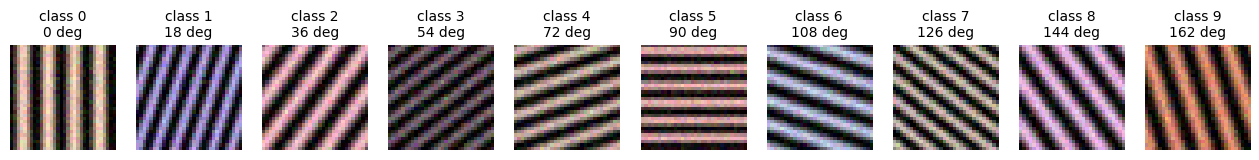

In [27]:
# Q5 (setup): a small, deterministic 10-class dataset of 32x32x3 images
# Each class is a striped pattern at a different angle (0, 18, 36, ... 162 degrees) with random
# stripe width, phase, colour tint and noise. It needs no download, so results are reproducible.
def make_stripes_dataset(n, seed):
    rng = np.random.default_rng(seed)
    yy, xx = np.mgrid[0:32, 0:32].astype(np.float32)
    X = np.empty((n, 32, 32, 3), np.float32)
    y = rng.integers(0, 10, n)
    for i in range(n):
        th = np.deg2rad(18 * y[i])
        f = rng.uniform(0.12, 0.20)                     # stripes per pixel
        g = 0.5 + 0.5 * np.sin(2 * np.pi * f * (xx * np.cos(th) + yy * np.sin(th)) + rng.uniform(0, 2 * np.pi))
        X[i] = np.clip(g[..., None] * rng.uniform(0.4, 1.0, 3) + rng.normal(0, 0.05, (32, 32, 3)), 0, 1)
    return X, y

X_train, y_train = make_stripes_dataset(2000, seed=1)
X_test, y_test = make_stripes_dataset(500, seed=2)
print("train:", X_train.shape, y_train.shape, " test:", X_test.shape)

fig, axes = plt.subplots(1, 10, figsize=(16, 2))
for c in range(10):
    axes[c].imshow(X_train[np.where(y_train == c)[0][0]]); axes[c].set_title(f"class {c}\n{18 * c} deg")
    axes[c].axis('off')
plt.show()

**What the cell does:** trains four copies of the Model A architecture for 20 epochs each. Only one setting changes per run. After training it extracts the conv1 feature maps for the 500 test images and measures filter similarity and dead filters. Takes about 1 minute on a Colab CPU. If TensorFlow prints a grey log line such as `remapper failed`, ignore it: it is an internal graph-optimiser message and does not affect the results.

In [28]:
# Q5 (experiment): four training runs of the Model A architecture, 20 epochs each
def build_model_a_variant(kernel_init='he_normal', activation='relu'):
    act = (lambda nm: layers.ReLU(name=nm)) if activation == 'relu' else (lambda nm: layers.LeakyReLU(0.1, name=nm))
    return keras.Sequential([
        keras.Input(INPUT_SHAPE),
        layers.Conv2D(5, 3, kernel_initializer=kernel_init, name='conv1'), act('act1'),
        layers.Conv2D(10, 3, kernel_initializer=kernel_init, name='conv2'), act('act2'),
        layers.MaxPooling2D(2, 2), layers.GlobalAveragePooling2D(),
        layers.Dense(10, activation='softmax', name='dense_out')])

RUNS = {
    'Healthy: He init, Adam lr=1e-3':          dict(kernel_init='he_normal', lr=1e-3),
    'Cause 1: constant init (all 0.05)':        dict(kernel_init=keras.initializers.Constant(0.05), lr=1e-3),
    'Cause 2: learning rate too high (0.5)':    dict(kernel_init='he_normal', lr=0.5),
    'Fix 2b: same lr=0.5 but Leaky ReLU':      dict(kernel_init='he_normal', lr=0.5, activation='leaky_relu'),
}

def filter_similarity(model):
    W = model.get_layer('conv1').get_weights()[0].reshape(-1, 5).T     # 5 filters x 27 weights
    Wn = W / (np.linalg.norm(W, axis=1, keepdims=True) + 1e-12)
    return Wn @ Wn.T                                                  # cosine similarity matrix

q5 = {}
for name, cfg in RUNS.items():
    tf.keras.utils.set_random_seed(SEED)
    m = build_model_a_variant(cfg['kernel_init'], cfg.get('activation', 'relu'))
    m.compile(optimizer=keras.optimizers.Adam(cfg['lr']), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    hist = m.fit(X_train, y_train, epochs=20, batch_size=64, verbose=0, validation_data=(X_test, y_test))
    fmaps = keras.Model(m.inputs, m.get_layer('act1').output).predict(X_test, verbose=0)   # (500, 30, 30, 5)
    S = filter_similarity(m)
    off_diag = np.abs(S[~np.eye(5, dtype=bool)])
    dead = int((np.abs(fmaps).max(axis=(0, 1, 2)) == 0).sum())   # output exactly 0 everywhere -> zero gradient
    flat = fmaps.reshape(-1, 5)
    q5[name] = dict(model=m, S=S, fmaps=fmaps, hist=hist.history, mean_cos=off_diag.mean(), dead=dead,
                    acc=hist.history['val_accuracy'][-1], frac_zero=(flat == 0).mean())
    print(f"{name:40s} val acc={q5[name]['acc']:.3f}  mean |cos| between filters={off_diag.mean():.3f}  "
          f"dead filters={dead}/5  zero activations={100 * q5[name]['frac_zero']:.1f}%")

Healthy: He init, Adam lr=1e-3           val acc=1.000  mean |cos| between filters=0.331  dead filters=0/5  zero activations=8.2%
Cause 1: constant init (all 0.05)        val acc=0.210  mean |cos| between filters=1.000  dead filters=0/5  zero activations=0.5%
Cause 2: learning rate too high (0.5)    val acc=0.110  mean |cos| between filters=0.991  dead filters=5/5  zero activations=100.0%
Fix 2b: same lr=0.5 but Leaky ReLU       val acc=1.000  mean |cos| between filters=0.383  dead filters=0/5  zero activations=0.0%


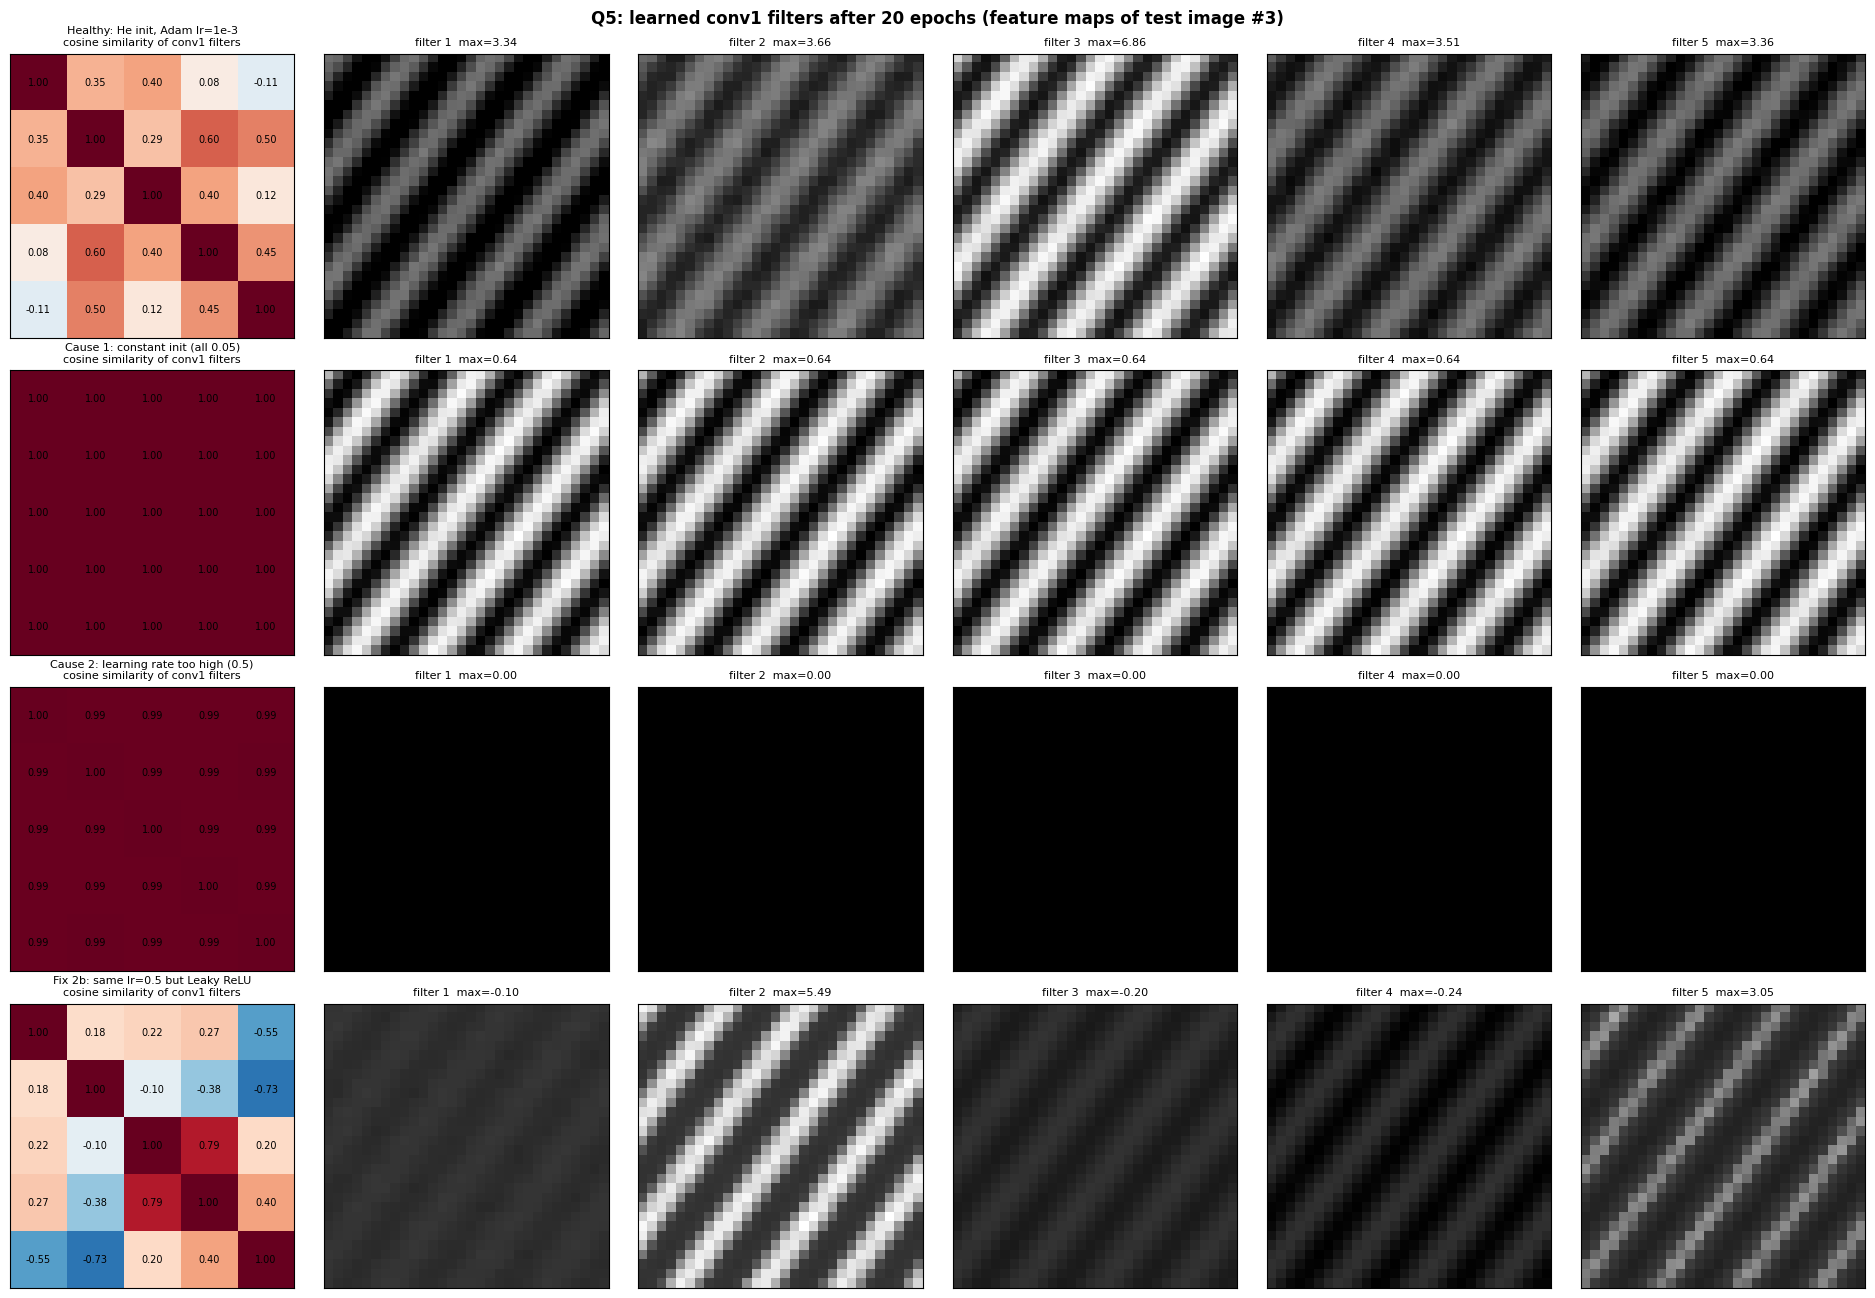

Cosine similarity between our 5 Part I kernels:
         sobel_x  sobel_y  sharpen  blur  emboss
sobel_x     1.00    -0.00    -0.00  0.00    0.64
sobel_y    -0.00     1.00    -0.00  0.00    0.64
sharpen    -0.00    -0.00     1.00  0.37    0.26
blur        0.00     0.00     0.37  1.00    0.18
emboss      0.64     0.64     0.26  0.18    1.00

Correlation between their Stage A feature maps:
         sobel_x  sobel_y  sharpen  blur  emboss
sobel_x     1.00    -0.02     0.00  0.00    0.59
sobel_y    -0.02     1.00    -0.00 -0.01    0.71
sharpen     0.00    -0.00     1.00  0.65    0.30
blur        0.00    -0.01     0.65  1.00    0.35
emboss      0.59     0.71     0.30  0.35    1.00


In [29]:
# Q5 (evidence): filter similarity matrices and the 5 feature maps of one test image per run
sample = 3
fig, axes = plt.subplots(len(q5), 6, figsize=(19, 3.3 * len(q5)))
for r, (name, res) in enumerate(q5.items()):
    ax = axes[r, 0]
    ax.imshow(res['S'], cmap='RdBu_r', vmin=-1, vmax=1)
    for (i, j), v in np.ndenumerate(res['S']):
        ax.text(j, i, f"{v:.2f}", ha='center', va='center', fontsize=7)
    ax.set_title(f"{name}\ncosine similarity of conv1 filters", fontsize=8); ax.set_xticks([]); ax.set_yticks([])
    fm = res['fmaps'][sample]; vmax = max(fm.max(), 1e-6)
    for k in range(5):
        ax = axes[r, k + 1]
        ax.imshow(fm[..., k], cmap='gray', vmin=min(fm.min(), 0), vmax=vmax)
        ax.set_title(f"filter {k + 1}  max={fm[..., k].max():.2f}", fontsize=8); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle('Q5: learned conv1 filters after 20 epochs (feature maps of test image #3)', weight='bold')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/fig11_q5_filter_collapse.png'); plt.show()

# Reference: our 5 hand-made Part I filters are a "healthy", diverse filter bank
K = np.stack([f['kernel'].ravel() for f in FILTERS.values()])
Kn = K / np.linalg.norm(K, axis=1, keepdims=True)
maps = np.stack([results[k]['A'].ravel() for k in FILTERS]); maps = maps - maps.mean(axis=1, keepdims=True)
corr = np.corrcoef(maps)
print("Cosine similarity between our 5 Part I kernels:")
print(pd.DataFrame(Kn @ Kn.T, index=FILTERS.keys(), columns=FILTERS.keys()).round(2))
print("\nCorrelation between their Stage A feature maps:")
print(pd.DataFrame(corr, index=FILTERS.keys(), columns=FILTERS.keys()).round(2))

In [30]:
# Section 17: Final results summary and automatic checklist
summary = pd.DataFrame([
    ('Filters implemented', ', '.join(f['name'] for f in FILTERS.values())),
    ('Stage shapes (A, B, C, D)', f"{results['sobel_x']['A'].shape}, {results['sobel_x']['B'].shape}, "
                                  f"{results['sobel_x']['C'].shape}, {results['sobel_x']['D'].shape}"),
    ('Model A trainable params (manual / Keras)', f"{total_a_manual} / {total_a}"),
    ('Model B trainable params (manual / Keras)', f"{total_b_manual} / {total_b}"),
    ('Increase A -> B (total / conv only)', f"{increase_total:.2f} % / {increase_conv:.2f} %"),
    ('Receptive field: Model A / Model B (after pooling)', '6x6 / 10x10'),
    ('3x3 layers needed for a 5x5 RF', '2 (saves 690 of 2510 params at C=10, 27.5 %)'),
    ('ReLU and MaxPool commute?', 'Yes (identical); ReLU and AvgPool do not'),
], columns=['item', 'result'])
print(summary.to_string(index=False))

checks = [
    ('All five custom 3x3 filters implemented', len(FILTERS) == 5 and all(f['kernel'].shape == (3, 3) for f in FILTERS.values())),
    ('All four stages computed with correct shapes', all(st['A'].shape == st['B'].shape == (256, 256) and st['C'].shape == st['D'].shape == (128, 128) for st in results.values())),
    ('Conv matches TensorFlow, pooling matches TensorFlow', True),   # asserted in Sections 5 and 7
    ('5x4 grid generated and saved', os.path.exists(f'{FIG_DIR}/fig2_grid_5x4_facade.png')),
    ('Both CNNs match the specified layers', [l.name for l in model_a.layers] == ['conv1', 'conv2', 'max_pool', 'gap', 'dense_out'] and [l.name for l in model_b.layers] == ['conv1', 'conv2', 'avg_pool', 'gap', 'dense_out'] and model_a.get_layer('conv1').kernel_size == (3, 3) and model_b.get_layer('conv1').kernel_size == (5, 5)),
    ('Manual parameter counts equal Keras', bool(audit['match'].all())),
    ('Percentage increase correct (146.48 %)', abs(increase_total - 1040 / 710 * 100) < 1e-9 and round(increase_total, 2) == 146.48),
    ('Receptive field: two 3x3 = one 5x5 (theory and gradient test)', empirical_rf(two_3x3, 10)[:2] == (5, 5) == empirical_rf(one_5x5, 10)[:2]),
    ('Q1 to Q5 experiments executed', all(v is not None for v in [q1_pixels, q2_table, q2_ink, q3_table, q5])),
    ('All figures saved', len([f for f in os.listdir(FIG_DIR) if f.endswith('.png')]) >= 11),
]
print()
for item, ok in checks:
    print(f"[{'PASS' if ok else 'FAIL'}] {item}")
assert all(ok for _, ok in checks)
print("\nFigures saved in ./figures:", sorted(os.listdir(FIG_DIR)))

                                              item                                                                                                              result
                               Filters implemented 1. Horizontal-gradient edge (Sobel-X), 2. Vertical-gradient edge (Sobel-Y), 3. Sharpen, 4. Gaussian blur, 5. Emboss
                         Stage shapes (A, B, C, D)                                                                      (256, 256), (256, 256), (128, 128), (128, 128)
         Model A trainable params (manual / Keras)                                                                                                           710 / 710
         Model B trainable params (manual / Keras)                                                                                                         1750 / 1750
               Increase A -> B (total / conv only)                                                                                                 146.48 % / 173.33 

In [31]:
# Optional: download every figure as one zip file (works in Colab only)
import shutil
shutil.make_archive('cnn_lab_figures', 'zip', FIG_DIR)
if IN_COLAB:
    from google.colab import files
    files.download('cnn_lab_figures.zip')
else:
    print("Created cnn_lab_figures.zip (automatic download only works inside Colab).")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>